###Intelligent Wine Quality Prediction and Multidimensional Analysis

WINE QUALITY PREDICTION & MULTIDIMENSIONAL ANALYSIS — PROJECT WRAP-UP

1. Dataset & Target Mapping
- Sources: Red wine (1,599 rows) + White wine (4,898 rows) = 6,497 raw rows (5,320 deduplicated after removing 1,177 duplicates; 0 missing values).
- Features: 11 physicochemical features + wine_type/is_white + derived chemistry ratios/differences.
- Quality Tiers: Low (3-4), Average (5-6), and High (7-9).

2. Methodologies Covered
- EDA & Correlations: Alcohol (+0.4694) leads positive correlation with quality; density (-0.3264), volatile acidity (-0.2652), and chlorides (-0.2021) lead negative correlations.
- Unsupervised & Dimensionality: K-Means, GMM, Hierarchical Clustering, PCA, t-SNE, UMAP, and Isolation Forest anomaly detection.
- Regression & Sequence: Linear, Ridge, Lasso, Bayesian Ridge regression, and Gaussian HMM sequence modeling.
- Classification & Ensembles: CART, Logistic Regression, Decision Tree, Random Forest, Gradient Boosting/XGBoost, KNN, Naive Bayes, MLP, Extra Trees, Voting, and Stacking.

3. Validation, Explainability & Reliability
- Stratified K-Fold CV, Grid/Random Search, confusion matrices, ROC-AUC, Precision/Recall/F1, learning curves, SHAP, LIME, permutation importance, partial dependence, calibration (Brier, ECE, log loss), and uncertainty (tree std, entropy, top-2 margin).

4. Best Model & Artifacts
- Top Classifier: Extra Trees (Balanced + Engineered Features) -> Test Accuracy: 0.7491 | Test Macro-F1: 0.6016 | Macro OVR ROC-AUC: 0.8555.
- Saved & Exported: wine_quality_et_pipeline.joblib, wine_quality_leaderboard.csv, wine_counterfactuals.csv, wine_project_summary.json, and model_monitoring_log.csv.

In [3]:
# Cell 1: Import data and visualization libraries
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("Running in Colab:", "COLAB_RELEASE_TAG" in os.environ)
print("Current working directory:", os.getcwd())

Running in Colab: True
Current working directory: /content


In [4]:
# Cell 2: Load datasets

red_path = "winequality-red.csv"
white_path = "winequality-white.csv"

red = pd.read_csv(red_path, sep=";")
white = pd.read_csv(white_path, sep=";")

# Fallback if files use commas instead of semicolons
if red.shape[1] == 1:
  red = pd.read_csv(red_path)
if white.shape[1] == 1:
  white = pd.read_csv(white_path)

red["wine_type"] = "red"
white["wine_type"] = "white"

df = pd.concat([red, white], ignore_index=True)
print("Datasets loaded successfully.")

Datasets loaded successfully.


In [5]:
# Cell 3: Inspect shapes, data types, missingness, duplicates, and sample rows
print(f"Red wine shape:     {red.shape}")
print(f"White wine shape:   {white.shape}")
print(f"Combined wine shape:{df.shape}")
print(f"Total missing values: {df.isnull().sum().sum()}")
print(f"Total exact duplicate rows: {df.duplicated().sum()}\n")

print("--- Column Data Types ---")
print(df.dtypes)

print("\n--- First 5 Rows (Combined) ---")
display(df.head())

print("\n--- Last 5 Rows (Combined) ---")
display(df.tail())

print("\n--- Quick Summary Statistics ---")
display(df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(3))

Red wine shape:     (1599, 13)
White wine shape:   (4898, 13)
Combined wine shape:(6497, 13)
Total missing values: 0
Total exact duplicate rows: 1177

--- Column Data Types ---
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                object
dtype: object

--- First 5 Rows (Combined) ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red



--- Last 5 Rows (Combined) ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white
6496,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6,white



--- Quick Summary Statistics ---


,count,mean,std,min,50%,max
fixed acidity,6497.0,7.215,1.296,3.800,7.000,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.290,1.580
citric acid,6497.0,0.319,0.145,0.000,0.310,1.660
residual sugar,6497.0,5.443,4.758,0.600,3.000,65.800
chlorides,6497.0,0.056,0.035,0.009,0.047,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,29.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,118.000,440.000
density,6497.0,0.995,0.003,0.987,0.995,1.039
pH,6497.0,3.219,0.161,2.720,3.210,4.010
sulphates,6497.0,0.531,0.149,0.220,0.510,2.000


In [6]:
# Cell 4: Compute detailed summary stats, IQR, and skewness across all numeric features
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

stats_df = df[num_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
stats_df["q25"] = df[num_cols].quantile(0.25)
stats_df["q75"] = df[num_cols].quantile(0.75)
stats_df["iqr"] = stats_df["q75"] - stats_df["q25"]
stats_df["skewness"] = df[num_cols].skew()

cols_order = [
    "count",
    "mean",
    "median",
    "std",
    "q25",
    "q75",
    "iqr",
    "skewness",
    "min",
    "max",
]
display(stats_df[cols_order].round(4))

,count,mean,median,std,q25,q75,iqr,skewness,min,max
fixed acidity,6497.0,7.2153,7.0000,1.2964,6.4000,7.700,1.3000,1.7233,3.8000,15.900
volatile acidity,6497.0,0.3397,0.2900,0.1646,0.2300,0.400,0.1700,1.4951,0.0800,1.580
citric acid,6497.0,0.3186,0.3100,0.1453,0.2500,0.390,0.1400,0.4717,0.0000,1.660
residual sugar,6497.0,5.4432,3.0000,4.7578,1.8000,8.100,6.3000,1.4354,0.6000,65.800
chlorides,6497.0,0.0560,0.0470,0.0350,0.0380,0.065,0.0270,5.3998,0.0090,0.611
free sulfur dioxide,6497.0,30.5253,29.0000,17.7494,17.0000,41.000,24.0000,1.2201,1.0000,289.000
total sulfur dioxide,6497.0,115.7446,118.0000,56.5219,77.0000,156.000,79.0000,-0.0012,6.0000,440.000
density,6497.0,0.9947,0.9949,0.0030,0.9923,0.997,0.0047,0.5036,0.9871,1.039
pH,6497.0,3.2185,3.2100,0.1608,3.1100,3.320,0.2100,0.3868,2.7200,4.010
sulphates,6497.0,0.5313,0.5100,0.1488,0.4300,0.600,0.1700,1.7973,0.2200,2.000


In [7]:
# Cell 5: Compare red and white wine means/medians and inspect quality score distribution
feature_cols = [c for c in num_cols if c != "quality"]

print("--- Mean Comparison: Red vs. White ---")
display(df.groupby("wine_type")[feature_cols].mean().T.round(4))

print("--- Median Comparison: Red vs. White ---")
display(df.groupby("wine_type")[feature_cols].median().T.round(4))

print("--- Quality Score Counts & Row Percentages ---")
q_counts = pd.crosstab(df["quality"], df["wine_type"], margins=True)
q_pct = (
    pd.crosstab(df["quality"], df["wine_type"], normalize="columns") * 100
).round(2)
display(q_counts)
display(q_pct.add_suffix(" (%)"))

--- Mean Comparison: Red vs. White ---


wine_type,red,white
fixed acidity,8.3196,6.8548
volatile acidity,0.5278,0.2782
citric acid,0.2710,0.3342
residual sugar,2.5388,6.3914
chlorides,0.0875,0.0458
free sulfur dioxide,15.8749,35.3081
total sulfur dioxide,46.4678,138.3607
density,0.9967,0.9940
pH,3.3111,3.1883
sulphates,0.6581,0.4898


--- Median Comparison: Red vs. White ---


wine_type,red,white
fixed acidity,7.9000,6.8000
volatile acidity,0.5200,0.2600
citric acid,0.2600,0.3200
residual sugar,2.2000,5.2000
chlorides,0.0790,0.0430
free sulfur dioxide,14.0000,34.0000
total sulfur dioxide,38.0000,134.0000
density,0.9968,0.9937
pH,3.3100,3.1800
sulphates,0.6200,0.4700


--- Quality Score Counts & Row Percentages ---


wine_type,red,white,All
quality,,,
3,10,20,30
4,53,163,216
5,681,1457,2138
6,638,2198,2836
7,199,880,1079
8,18,175,193
9,0,5,5
All,1599,4898,6497


wine_type,red (%),white (%)
quality,,
3,0.63,0.41
4,3.31,3.33
5,42.59,29.75
6,39.90,44.88
7,12.45,17.97
8,1.13,3.57
9,0.00,0.10


In [8]:
# Cell 6: Flag values outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR] (for inspection, not blind deletion)
outlier_rows = []
for col in feature_cols:
  q1, q3 = df[col].quantile([0.25, 0.75])
  iqr = q3 - q1
  low_bound = q1 - 1.5 * iqr
  high_bound = q3 + 1.5 * iqr
  mask = (df[col] < low_bound) | (df[col] > high_bound)
  outlier_rows.append({
      "feature": col,
      "lower_fence": round(low_bound, 4),
      "upper_fence": round(high_bound, 4),
      "iqr_flagged_count": int(mask.sum()),
      "iqr_flagged_pct": round(mask.mean() * 100, 2),
  })

display(pd.DataFrame(outlier_rows))

,feature,lower_fence,upper_fence,iqr_flagged_count,iqr_flagged_pct
0,fixed acidity,4.4500,9.6500,357,5.49
1,volatile acidity,-0.0250,0.6550,377,5.80
2,citric acid,0.0400,0.6000,509,7.83
3,residual sugar,-7.6500,17.5500,118,1.82
4,chlorides,-0.0025,0.1055,286,4.40
5,free sulfur dioxide,-19.0000,77.0000,62,0.95
6,total sulfur dioxide,-41.5000,274.5000,10,0.15
7,density,0.9854,1.0040,3,0.05
8,pH,2.7950,3.6350,73,1.12
9,sulphates,0.1750,0.8550,191,2.94


In [9]:
# Cell 7: Deduplicate to prevent split leakage, encode wine_type, and train OLS pipeline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Deduplicate combined dataset while keeping exact chemical rows intact within each split
df_clean = df.drop_duplicates().reset_index(drop=True)
df_clean["is_white"] = (df_clean["wine_type"] == "white").astype(int)

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
target_col = "quality"

X = df_clean[feature_cols]
y = df_clean[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=df_clean["wine_type"]
)

linreg_pipe = Pipeline(
    [("scaler", StandardScaler()), ("model", LinearRegression())]
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(linreg_pipe, X_train, y_train, cv=kf, scoring="r2")
cv_rmse = -cross_val_score(
    linreg_pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error"
)

linreg_pipe.fit(X_train, y_train)
y_pred_train = linreg_pipe.predict(X_train)
y_pred_test = linreg_pipe.predict(X_test)
y_pred_test_clipped = np.clip(y_pred_test, 3.0, 9.0)

print(
    f"Train R2: {r2_score(y_train, y_pred_train):.4f} | Train RMSE:"
    f" {root_mean_squared_error(y_train, y_pred_train):.4f} | Train MAE:"
    f" {mean_absolute_error(y_train, y_pred_train):.4f}"
)
print(
    f"5-Fold CV R2: {cv_r2.mean():.4f} (+/- {cv_r2.std():.4f}) | 5-Fold CV RMSE:"
    f" {cv_rmse.mean():.4f}"
)
print(
    f"Test R2:  {r2_score(y_test, y_pred_test):.4f} | Test RMSE:"
    f" {root_mean_squared_error(y_test, y_pred_test):.4f} | Test MAE:"
    f" {mean_absolute_error(y_test, y_pred_test):.4f}"
)
print(
    "Test R2 (Clipped 3-9):"
    f" {r2_score(y_test, y_pred_test_clipped):.4f} | Clipped RMSE:"
    f" {root_mean_squared_error(y_test, y_pred_test_clipped):.4f} |"
    f" Clipped MAE: {mean_absolute_error(y_test, y_pred_test_clipped):.4f}"
)

Train R2: 0.3192 | Train RMSE: 0.7313 | Train MAE: 0.5669
5-Fold CV R2: 0.3101 (+/- 0.0060) | 5-Fold CV RMSE: 0.7358
Test R2:  0.2738 | Test RMSE: 0.7262 | Test MAE: 0.5522
Test R2 (Clipped 3-9): 0.2738 | Clipped RMSE: 0.7262 | Clipped MAE: 0.5522


In [10]:
# Cell 8: Inspect standardized coefficients, RidgeCV/LassoCV, and cross-style transfer
coef_table = pd.DataFrame({
    "feature": feature_cols,
    "standardized_coef": linreg_pipe.named_steps["model"].coef_,
}).sort_values("standardized_coef", key=abs, ascending=False)

print(
    "Intercept (at training feature means):"
    f" {linreg_pipe.named_steps['model'].intercept_:.4f}"
)
display(coef_table.round(4))

# Regularized linear baselines for comparison
ridge_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RidgeCV(alphas=np.logspace(-2, 3, 50))),
])
lasso_pipe = Pipeline(
    [("scaler", StandardScaler()), ("model", LassoCV(cv=5, random_state=42))]
)

ridge_pipe.fit(X_train, y_train)
lasso_pipe.fit(X_train, y_train)

print(
    f"RidgeCV (alpha={ridge_pipe.named_steps['model'].alpha_:.4f}) -> Test R2:"
    f" {r2_score(y_test, ridge_pipe.predict(X_test)):.4f}, RMSE:"
    f" {root_mean_squared_error(y_test, ridge_pipe.predict(X_test)):.4f}"
)
print(
    f"LassoCV (alpha={lasso_pipe.named_steps['model'].alpha_:.4f}) -> Test R2:"
    f" {r2_score(y_test, lasso_pipe.predict(X_test)):.4f}, RMSE:"
    f" {root_mean_squared_error(y_test, lasso_pipe.predict(X_test)):.4f}"
)

# Unique domain-shift check: train on one wine style, evaluate on the other
chem_cols = [c for c in feature_cols if c != "is_white"]
w_sub = df_clean[df_clean["wine_type"] == "white"]
r_sub = df_clean[df_clean["wine_type"] == "red"]

m_w2r = Pipeline(
    [("scaler", StandardScaler()), ("model", LinearRegression())]
).fit(w_sub[chem_cols], w_sub["quality"])
pred_w2r = m_w2r.predict(r_sub[chem_cols])

m_r2w = Pipeline(
    [("scaler", StandardScaler()), ("model", LinearRegression())]
).fit(r_sub[chem_cols], r_sub["quality"])
pred_r2w = m_r2w.predict(w_sub[chem_cols])

print(
    f"White -> Red transfer | R2: {r2_score(r_sub['quality'], pred_w2r):.4f} |"
    f" RMSE: {root_mean_squared_error(r_sub['quality'], pred_w2r):.4f} | MAE:"
    f" {mean_absolute_error(r_sub['quality'], pred_w2r):.4f}"
)
print(
    f"Red -> White transfer | R2: {r2_score(w_sub['quality'], pred_r2w):.4f} |"
    f" RMSE: {root_mean_squared_error(w_sub['quality'], pred_r2w):.4f} | MAE:"
    f" {mean_absolute_error(w_sub['quality'], pred_r2w):.4f}"
)

Intercept (at training feature means): 5.8005


,feature,standardized_coef
7,density,-0.3239
10,alcohol,0.2732
3,residual sugar,0.2650
1,volatile acidity,-0.2258
11,is_white,-0.1408
0,fixed acidity,0.1252
8,pH,0.1150
9,sulphates,0.1147
5,free sulfur dioxide,0.1031
6,total sulfur dioxide,-0.0787


RidgeCV (alpha=37.2759) -> Test R2: 0.2752, RMSE: 0.7255
LassoCV (alpha=0.0018) -> Test R2: 0.2752, RMSE: 0.7255
White -> Red transfer | R2: -0.3465 | RMSE: 0.9553 | MAE: 0.7814
Red -> White transfer | R2: 0.2294 | RMSE: 0.7818 | MAE: 0.6052


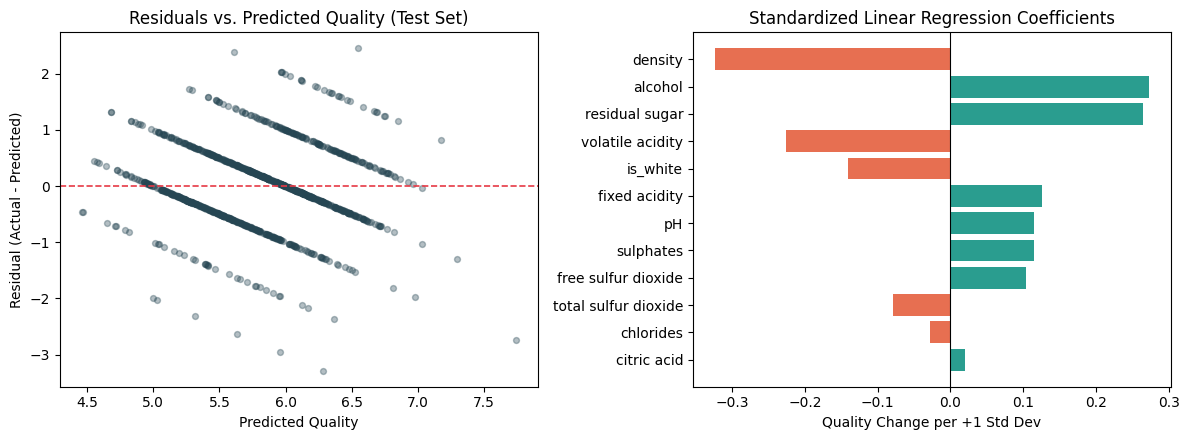

Test row 3155 -> Actual: 6, Predicted: {'raw_prediction': 6.2733, 'clipped_prediction': 6.2733}


In [11]:
# Cell 9: Plot residuals vs. predictions and standardized coefficients, plus single-sample inference
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

residuals = y_test - y_pred_test
axes[0].scatter(y_pred_test, residuals, alpha=0.35, s=18, color="#264653")
axes[0].axhline(0, color="#e63946", linestyle="--", linewidth=1.2)
axes[0].set_title("Residuals vs. Predicted Quality (Test Set)")
axes[0].set_xlabel("Predicted Quality")
axes[0].set_ylabel("Residual (Actual - Predicted)")

plot_coefs = coef_table.iloc[::-1]
bar_colors = [
    "#2a9d8f" if val > 0 else "#e76f51" for val in plot_coefs["standardized_coef"]
]
axes[1].barh(
    plot_coefs["feature"], plot_coefs["standardized_coef"], color=bar_colors
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Standardized Linear Regression Coefficients")
axes[1].set_xlabel("Quality Change per +1 Std Dev")

plt.tight_layout()
plt.show()


def predict_wine_quality(sample_dict, model_pipeline=linreg_pipe):
  """Predict quality score from a dictionary of physicochemical attributes and wine_type."""
  row = sample_dict.copy()
  if "is_white" not in row:
    w_type = str(row.get("wine_type", "white")).strip().lower()
    row["is_white"] = 1 if w_type == "white" else 0
  sample_df = pd.DataFrame([row])[feature_cols]
  raw_pred = float(model_pipeline.predict(sample_df)[0])
  clipped_pred = float(np.clip(raw_pred, 3.0, 9.0))
  return {"raw_prediction": round(raw_pred, 4), "clipped_prediction": round(clipped_pred, 4)}


# Example using the first test sample
idx0 = X_test.index[0]
example_input = X_test.loc[idx0].to_dict()
print(
    f"Test row {idx0} -> Actual: {y_test.loc[idx0]}, Predicted:"
    f" {predict_wine_quality(example_input)}"
)

In [12]:
# Cell 10: Create quality tiers, split stratified by wine_type + tier, and fit BayesianRidge
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score, mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


def to_quality_tier(q):
  if q <= 4:
    return "Low (3-4)"
  elif q <= 6:
    return "Average (5-6)"
  else:
    return "High (7-9)"


df_clean = df.drop_duplicates().reset_index(drop=True)
df_clean["is_white"] = (df_clean["wine_type"] == "white").astype(int)
df_clean["quality_tier"] = df_clean["quality"].apply(to_quality_tier)

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
X = df_clean[feature_cols]
y_reg = df_clean["quality"]
y_clf = df_clean["quality_tier"]
strat_col = df_clean["wine_type"] + "_" + df_clean["quality_tier"]

X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = (
    train_test_split(
        X, y_reg, y_clf, test_size=0.20, random_state=42, stratify=strat_col
    )
)

bayes_pipe = Pipeline(
    [("scaler", StandardScaler()), ("model", BayesianRidge())]
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(bayes_pipe, X_train, y_reg_train, cv=kf, scoring="r2")
cv_rmse = -cross_val_score(
    bayes_pipe, X_train, y_reg_train, cv=kf, scoring="neg_root_mean_squared_error"
)

bayes_pipe.fit(X_train, y_reg_train)
y_reg_pred, y_reg_std = bayes_pipe.predict(X_test, return_std=True)
y_reg_pred_clip = np.clip(y_reg_pred, 3.0, 9.0)

bayes_model = bayes_pipe.named_steps["model"]
coverage_95 = np.mean(np.abs(y_reg_test.values - y_reg_pred) <= 1.96 * y_reg_std)

print("=== Bayesian Ridge Regression ===")
print(
    f"5-Fold CV R2: {cv_r2.mean():.4f} (+/- {cv_r2.std():.4f}) | CV RMSE:"
    f" {cv_rmse.mean():.4f}"
)
print(
    f"Test R2: {r2_score(y_reg_test, y_reg_pred):.4f} | RMSE:"
    f" {root_mean_squared_error(y_reg_test, y_reg_pred):.4f} | MAE:"
    f" {mean_absolute_error(y_reg_test, y_reg_pred):.4f}"
)
print(
    f"Test R2 (Clipped 3-9): {r2_score(y_reg_test, y_reg_pred_clip):.4f} |"
    f" Clipped RMSE: {root_mean_squared_error(y_reg_test, y_reg_pred_clip):.4f}"
)
print(
    f"Learned alpha_ (noise precision): {bayes_model.alpha_:.4f} (noise std ~"
    f" {1/np.sqrt(bayes_model.alpha_):.4f})"
)
print(f"Learned lambda_ (weight precision): {bayes_model.lambda_:.4f}")
print(
    "Predictive std range on test set:"
    f" [{y_reg_std.min():.4f}, {y_reg_std.max():.4f}] (mean"
    f" {y_reg_std.mean():.4f})"
)
print(f"Empirical +/-1.96*std coverage on test set: {coverage_95*100:.2f}%")

=== Bayesian Ridge Regression ===
5-Fold CV R2: 0.2969 (+/- 0.0173) | CV RMSE: 0.7370
Test R2: 0.3434 | RMSE: 0.7132 | MAE: 0.5498
Test R2 (Clipped 3-9): 0.3434 | Clipped RMSE: 0.7132
Learned alpha_ (noise precision): 1.8475 (noise std ~ 0.7357)
Learned lambda_ (weight precision): 38.3872
Predictive std range on test set: [0.7358, 0.7621] (mean 0.7367)
Empirical +/-1.96*std coverage on test set: 94.36%


In [13]:
# Cell 11: Compare SVM variants for predicting Low / Average / High quality tiers
tier_order = ["Low (3-4)", "Average (5-6)", "High (7-9)"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidates = {
    "SVM RBF (C=1.0)": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42),
    "SVM RBF Balanced (C=1.0)": SVC(
        kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=42
    ),
    "SVM RBF Balanced (C=3.0)": SVC(
        kernel="rbf", C=3.0, gamma="scale", class_weight="balanced", random_state=42
    ),
    "SVM Linear Balanced (C=1.0)": SVC(
        kernel="linear", C=1.0, class_weight="balanced", random_state=42
    ),
}

results = []
fitted_pipes = {}

for name, clf in candidates.items():
  pipe = Pipeline([("scaler", StandardScaler()), ("clf", clf)])
  cv_f1 = cross_val_score(pipe, X_train, y_clf_train, cv=skf, scoring="f1_macro")
  pipe.fit(X_train, y_clf_train)
  preds = pipe.predict(X_test)
  fitted_pipes[name] = (pipe, preds)
  results.append({
      "model": name,
      "cv_macro_f1": round(cv_f1.mean(), 4),
      "test_accuracy": round(accuracy_score(y_clf_test, preds), 4),
      "test_macro_f1": round(
          f1_score(y_clf_test, preds, labels=tier_order, average="macro"), 4
      ),
      "test_weighted_f1": round(
          f1_score(y_clf_test, preds, labels=tier_order, average="weighted"), 4
      ),
  })

summary_svm = pd.DataFrame(results).sort_values("test_macro_f1", ascending=False)
display(summary_svm)

best_svm_name = summary_svm.iloc[0]["model"]
best_svm_pipe, best_svm_preds = fitted_pipes[best_svm_name]

print(f"\n=== Detailed Classification Report: {best_svm_name} ===")
print(
    classification_report(
        y_clf_test, best_svm_preds, labels=tier_order, digits=4
    )
)

,model,cv_macro_f1,test_accuracy,test_macro_f1,test_weighted_f1
2,SVM RBF Balanced (C=3.0),0.5158,0.6570,0.5380,0.6863
1,SVM RBF Balanced (C=1.0),0.5099,0.6429,0.5360,0.6747
3,SVM Linear Balanced (C=1.0),0.4633,0.5836,0.4817,0.6223
0,SVM RBF (C=1.0),0.4122,0.8073,0.4385,0.7596



=== Detailed Classification Report: SVM RBF Balanced (C=3.0) ===
               precision    recall  f1-score   support

    Low (3-4)     0.2195    0.5625    0.3158        48
Average (5-6)     0.8982    0.6290    0.7399       814
   High (7-9)     0.4313    0.7921    0.5585       202

     accuracy                         0.6570      1064
    macro avg     0.5163    0.6612    0.5380      1064
 weighted avg     0.7790    0.6570    0.6863      1064



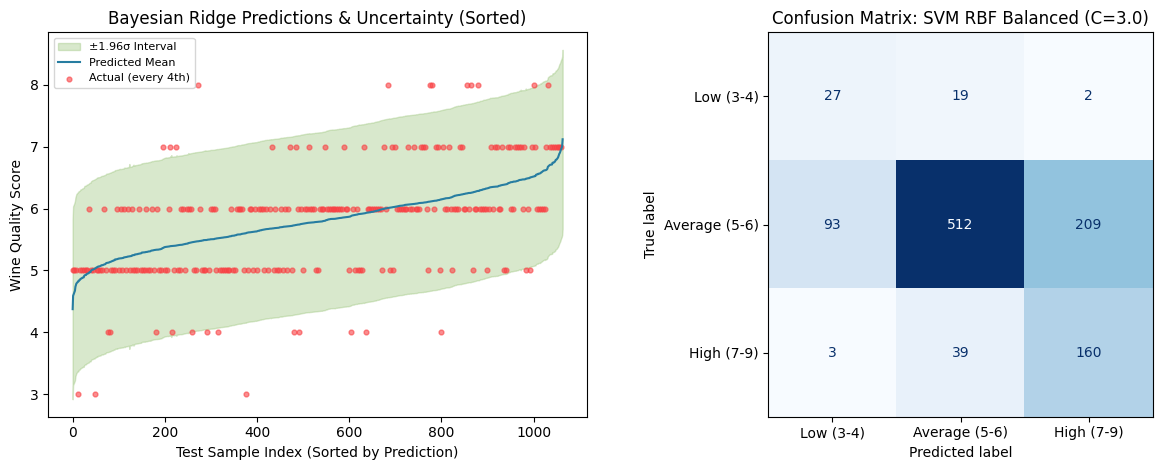

In [14]:
# Cell 12: Plot Bayesian Ridge uncertainty bounds and Best SVM confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

sort_order = np.argsort(y_reg_pred)
x_idx = np.arange(len(y_reg_pred))
p_sorted = y_reg_pred[sort_order]
s_sorted = y_reg_std[sort_order]
a_sorted = y_reg_test.values[sort_order]

axes[0].fill_between(
    x_idx,
    p_sorted - 1.96 * s_sorted,
    p_sorted + 1.96 * s_sorted,
    color="#90be6d",
    alpha=0.35,
    label="±1.96σ Interval",
)
axes[0].plot(
    x_idx, p_sorted, color="#277da1", linewidth=1.5, label="Predicted Mean"
)
axes[0].scatter(
    x_idx[::4],
    a_sorted[::4],
    color="#f94144",
    s=12,
    alpha=0.6,
    label="Actual (every 4th)",
)
axes[0].set_title("Bayesian Ridge Predictions & Uncertainty (Sorted)")
axes[0].set_xlabel("Test Sample Index (Sorted by Prediction)")
axes[0].set_ylabel("Wine Quality Score")
axes[0].legend(loc="upper left", fontsize=8)

cm = confusion_matrix(y_clf_test, best_svm_preds, labels=tier_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=tier_order)
disp.plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title(f"Confusion Matrix: {best_svm_name}")

plt.tight_layout()
plt.show()

In [15]:
# Cell 13: Standardize 11 chemical features and compare k = 2..6 for K-Means and GMM
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

df_clean = df.drop_duplicates().reset_index(drop=True)

chem_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[chem_cols])

k_values = [2, 3, 4, 5, 6]
k_eval = []

for k in k_values:
  km = KMeans(n_clusters=k, n_init=20, random_state=42)
  km_labels = km.fit_predict(X_scaled)

  gmm = GaussianMixture(
      n_components=k, covariance_type="full", n_init=10, random_state=42
  )
  gmm_labels = gmm.fit_predict(X_scaled)

  k_eval.append({
      "k": k,
      "kmeans_inertia": round(km.inertia_, 1),
      "kmeans_silhouette": round(silhouette_score(X_scaled, km_labels), 4),
      "gmm_bic": round(gmm.bic(X_scaled), 1),
      "gmm_aic": round(gmm.aic(X_scaled), 1),
      "gmm_silhouette": round(silhouette_score(X_scaled, gmm_labels), 4),
  })

display(pd.DataFrame(k_eval))

,k,kmeans_inertia,kmeans_silhouette,gmm_bic,gmm_aic,gmm_silhouette
0,2,46095.5,0.2704,119250.3,118230.5,0.2419
1,3,37914.9,0.2300,112236.9,110704.0,0.1632
2,4,33828.6,0.2428,111013.1,108967.0,0.1410
3,5,31544.2,0.1769,108534.0,105974.7,0.0656
4,6,29578.5,0.1838,107156.7,104084.2,0.0704


In [16]:
# Cell 14: Fit K-Means, GaussianMixture, and Ward Hierarchical Clustering at k=3
k_opt = 3

kmeans_model = KMeans(n_clusters=k_opt, n_init=20, random_state=42)
labels_km = kmeans_model.fit_predict(X_scaled)

gmm_model = GaussianMixture(
    n_components=k_opt, covariance_type="full", n_init=10, random_state=42
)
labels_gmm = gmm_model.fit_predict(X_scaled)

hier_model = AgglomerativeClustering(n_clusters=k_opt, linkage="ward")
labels_hc = hier_model.fit_predict(X_scaled)

df_clean["km_cluster"] = labels_km
df_clean["gmm_cluster"] = labels_gmm
df_clean["hc_cluster"] = labels_hc

print("=== Silhouette Scores (k=3) ===")
print(f"K-Means:      {silhouette_score(X_scaled, labels_km):.4f}")
print(f"GMM:          {silhouette_score(X_scaled, labels_gmm):.4f}")
print(f"Hierarchical: {silhouette_score(X_scaled, labels_hc):.4f}")

print("\n=== Pairwise Adjusted Rand Index (ARI) ===")
print(
    f"K-Means vs. GMM:          {adjusted_rand_score(labels_km, labels_gmm):.4f}"
)
print(
    "K-Means vs. Hierarchical:"
    f" {adjusted_rand_score(labels_km, labels_hc):.4f}"
)
print(
    f"GMM vs. Hierarchical:     {adjusted_rand_score(labels_gmm, labels_hc):.4f}"
)


def cluster_profile(df_in, col):
  prof = df_in.groupby(col)[chem_cols + ["quality"]].mean()
  prof["samples"] = df_in.groupby(col).size()
  prof["white_%"] = (
      df_in.groupby(col)["wine_type"].apply(lambda s: (s == "white").mean() * 100)
  ).round(1)
  return prof.round(3)


print("\n--- K-Means (k=3) Cluster Profiles ---")
display(cluster_profile(df_clean, "km_cluster"))

print("--- GMM (k=3) Cluster Profiles ---")
display(cluster_profile(df_clean, "gmm_cluster"))

print("--- Hierarchical Ward (k=3) Cluster Profiles ---")
display(cluster_profile(df_clean, "hc_cluster"))

=== Silhouette Scores (k=3) ===
K-Means:      0.2300
GMM:          0.1632
Hierarchical: 0.2145

=== Pairwise Adjusted Rand Index (ARI) ===
K-Means vs. GMM:          0.3118
K-Means vs. Hierarchical: 0.7946
GMM vs. Hierarchical:     0.3310

--- K-Means (k=3) Cluster Profiles ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,samples,white_%
km_cluster,,,,,,,,,,,,,,
0,6.956,0.287,0.361,10.656,0.054,46.143,171.251,0.997,3.166,0.493,9.619,5.562,1424,99.7
1,6.757,0.274,0.319,3.239,0.041,28.671,117.309,0.992,3.216,0.490,11.179,6.045,2542,98.0
2,8.349,0.537,0.273,2.548,0.090,15.662,48.005,0.997,3.303,0.657,10.345,5.573,1354,3.7


--- GMM (k=3) Cluster Profiles ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,samples,white_%
gmm_cluster,,,,,,,,,,,,,,
0,7.679,0.493,0.376,5.381,0.115,25.702,102.807,0.996,3.195,0.631,10.200,5.420,500,52.8
1,6.794,0.269,0.331,6.505,0.042,36.966,140.970,0.994,3.199,0.487,10.658,5.944,3236,99.8
2,7.929,0.450,0.276,1.968,0.069,17.249,62.802,0.995,3.285,0.597,10.437,5.610,1584,29.5


--- Hierarchical Ward (k=3) Cluster Profiles ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,samples,white_%
hc_cluster,,,,,,,,,,,,,,
0,8.185,0.521,0.280,2.633,0.092,17.285,54.629,0.997,3.297,0.647,10.375,5.592,1478,9.5
1,6.798,0.272,0.320,3.535,0.041,29.680,120.748,0.992,3.211,0.489,11.076,6.009,2662,99.3
2,6.941,0.284,0.362,11.487,0.049,46.815,173.633,0.997,3.166,0.490,9.579,5.569,1180,99.7


PC1 + PC2 explained variance: 27.17% + 22.50% = 49.67%


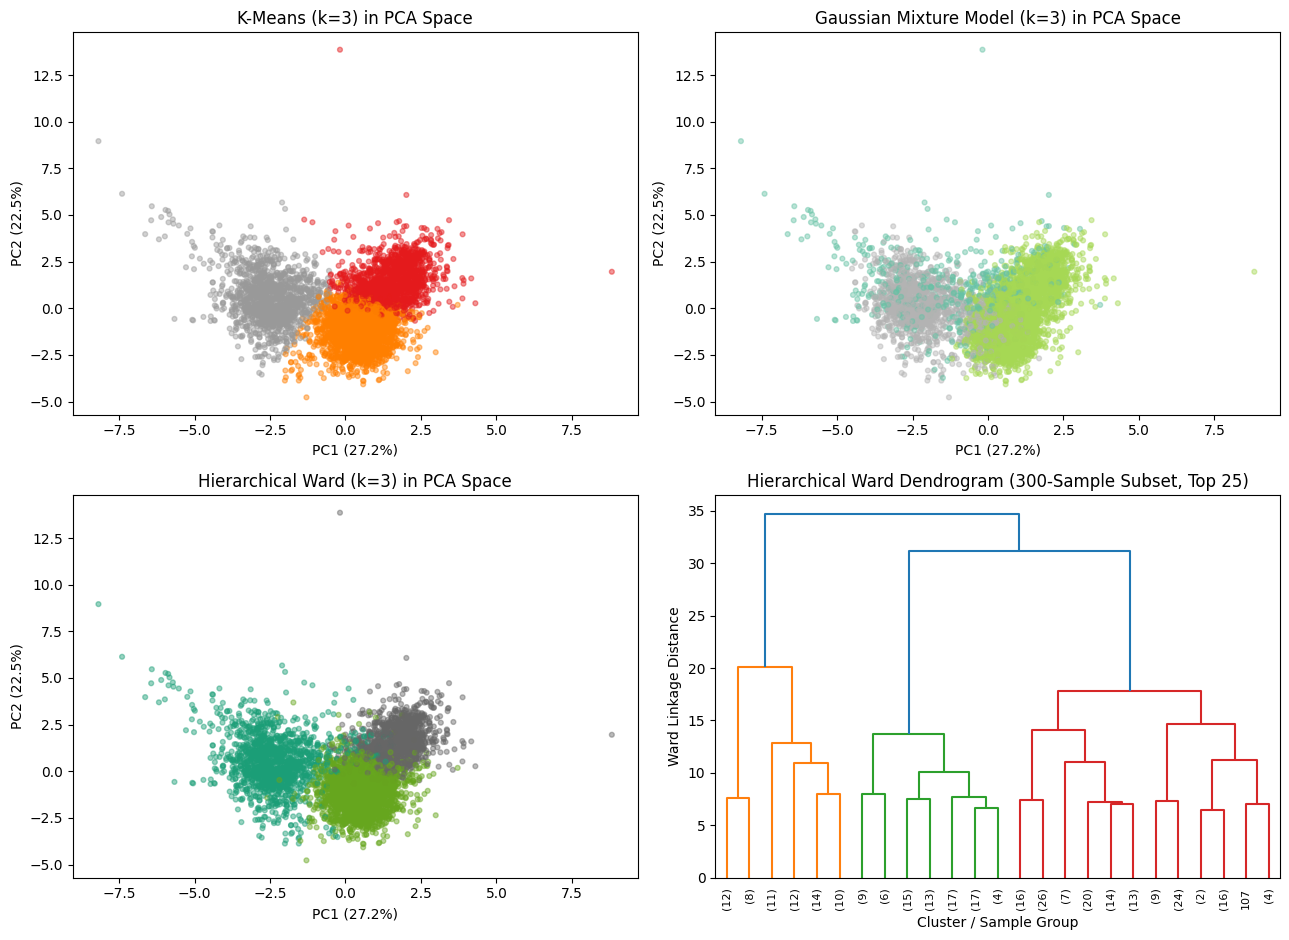

In [17]:
# Cell 15: Project onto top 2 PCs for scatter comparison and plot a 300-row dendrogram
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
pc1_var, pc2_var = pca.explained_variance_ratio_ * 100
print(
    f"PC1 + PC2 explained variance: {pc1_var:.2f}% + {pc2_var:.2f}% ="
    f" {pc1_var + pc2_var:.2f}%"
)

rng = np.random.default_rng(42)
sub_idx = rng.choice(len(X_scaled), size=300, replace=False)
Z_ward = linkage(X_scaled[sub_idx], method="ward")

fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))

axes[0, 0].scatter(
    X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap="Set1", alpha=0.45, s=12
)
axes[0, 0].set_title("K-Means (k=3) in PCA Space")
axes[0, 0].set_xlabel(f"PC1 ({pc1_var:.1f}%)")
axes[0, 0].set_ylabel(f"PC2 ({pc2_var:.1f}%)")

axes[0, 1].scatter(
    X_pca[:, 0], X_pca[:, 1], c=labels_gmm, cmap="Set2", alpha=0.45, s=12
)
axes[0, 1].set_title("Gaussian Mixture Model (k=3) in PCA Space")
axes[0, 1].set_xlabel(f"PC1 ({pc1_var:.1f}%)")
axes[0, 1].set_ylabel(f"PC2 ({pc2_var:.1f}%)")

axes[1, 0].scatter(
    X_pca[:, 0], X_pca[:, 1], c=labels_hc, cmap="Dark2", alpha=0.45, s=12
)
axes[1, 0].set_title("Hierarchical Ward (k=3) in PCA Space")
axes[1, 0].set_xlabel(f"PC1 ({pc1_var:.1f}%)")
axes[1, 0].set_ylabel(f"PC2 ({pc2_var:.1f}%)")

dendrogram(
    Z_ward,
    truncate_mode="lastp",
    p=25,
    ax=axes[1, 1],
    leaf_rotation=90,
    leaf_font_size=8,
)
axes[1, 1].set_title("Hierarchical Ward Dendrogram (300-Sample Subset, Top 25)")
axes[1, 1].set_xlabel("Cluster / Sample Group")
axes[1, 1].set_ylabel("Ward Linkage Distance")

plt.tight_layout()
plt.show()

In [18]:
# Cell 16: Fit full PCA on standardized chemical features and inspect variance ratios
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

df_clean = df.drop_duplicates().reset_index(drop=True)

chem_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[chem_cols])

pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_scaled)

evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
eigenvalues = pca_full.explained_variance_

pca_summary = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(chem_cols))],
    "eigenvalue": np.round(eigenvalues, 4),
    "explained_var_ratio": np.round(evr, 4),
    "explained_var_%": np.round(evr * 100, 2),
    "cumulative_var_%": np.round(cum_evr * 100, 2),
})
display(pca_summary)

n_80 = int(np.argmax(cum_evr >= 0.80) + 1)
n_90 = int(np.argmax(cum_evr >= 0.90) + 1)
n_95 = int(np.argmax(cum_evr >= 0.95) + 1)
n_kaiser = int((eigenvalues > 1.0).sum())

print(
    f"Components needed for >=80% variance: {n_80}"
    f" ({cum_evr[n_80-1]*100:.2f}%)"
)
print(
    f"Components needed for >=90% variance: {n_90}"
    f" ({cum_evr[n_90-1]*100:.2f}%)"
)
print(
    f"Components needed for >=95% variance: {n_95}"
    f" ({cum_evr[n_95-1]*100:.2f}%)"
)
print(f"Kaiser criterion (eigenvalue > 1):    {n_kaiser} components")

,PC,eigenvalue,explained_var_ratio,explained_var_%,cumulative_var_%
0,PC1,2.9889,0.2717,27.17,27.17
1,PC2,2.4757,0.2250,22.50,49.67
2,PC3,1.5876,0.1443,14.43,64.10
3,PC4,0.9536,0.0867,8.67,72.77
4,PC5,0.7424,0.0675,6.75,79.51
5,PC6,0.6272,0.0570,5.70,85.21
6,PC7,0.5211,0.0474,4.74,89.95
7,PC8,0.5077,0.0461,4.61,94.57
8,PC9,0.3368,0.0306,3.06,97.63
9,PC10,0.2260,0.0205,2.05,99.68


Components needed for >=80% variance: 6 (85.21%)
Components needed for >=90% variance: 8 (94.57%)
Components needed for >=95% variance: 9 (97.63%)
Kaiser criterion (eigenvalue > 1):    3 components


In [19]:
# Cell 17: Inspect loadings for top components and correlate PCs with quality & wine_type
loadings_df = pd.DataFrame(
    pca_full.components_[:4].T,
    index=chem_cols,
    columns=["PC1", "PC2", "PC3", "PC4"],
)
print("=== Loadings for PC1 - PC4 ===")
display(loadings_df.round(4))

print("=== Strongest Positive & Negative Loadings per PC ===")
for col in loadings_df.columns:
  s = loadings_df[col].sort_values()
  print(
      f"{col}: lowest = {s.index[0]} ({s.iloc[0]:.4f}),"
      f" {s.index[1]} ({s.iloc[1]:.4f}) | highest = {s.index[-1]}"
      f" ({s.iloc[-1]:.4f}), {s.index[-2]} ({s.iloc[-2]:.4f})"
  )

pc_corr_df = pd.DataFrame(
    X_pca_full[:, :4], columns=["PC1", "PC2", "PC3", "PC4"]
)
pc_corr_df["quality"] = df_clean["quality"].values
pc_corr_df["is_white"] = (df_clean["wine_type"] == "white").astype(int).values

print("\n=== Correlation of Top PCs with Quality and is_white ===")
display(
    pc_corr_df.corr()[["quality", "is_white"]]
    .loc[["PC1", "PC2", "PC3", "PC4"]]
    .round(4)
)

=== Loadings for PC1 - PC4 ===


,PC1,PC2,PC3,PC4
fixed acidity,-0.2749,0.3066,0.4238,-0.1946
volatile acidity,-0.3897,0.0695,-0.3119,-0.2325
citric acid,0.1340,0.2194,0.5772,0.2492
residual sugar,0.2976,0.3680,-0.1728,-0.1863
chlorides,-0.3196,0.2749,-0.0087,0.2914
free sulfur dioxide,0.4258,0.1412,-0.1384,0.3350
total sulfur dioxide,0.4763,0.1622,-0.1158,0.1977
density,-0.1366,0.5651,-0.1844,-0.0933
pH,-0.1879,-0.1873,-0.4645,0.3946
sulphates,-0.3176,0.1578,0.0740,0.6341


=== Strongest Positive & Negative Loadings per PC ===
PC1: lowest = volatile acidity (-0.3897), chlorides (-0.3196) | highest = total sulfur dioxide (0.4763), free sulfur dioxide (0.4258)
PC2: lowest = alcohol (-0.4652), pH (-0.1873) | highest = density (0.5651), residual sugar (0.3680)
PC3: lowest = pH (-0.4645), volatile acidity (-0.3119) | highest = citric acid (0.5772), fixed acidity (0.4238)
PC4: lowest = volatile acidity (-0.2325), fixed acidity (-0.1946) | highest = sulphates (0.6341), pH (0.3946)

=== Correlation of Top PCs with Quality and is_white ===


,quality,is_white
PC1,0.1121,0.8485
PC2,-0.3192,-0.1782
PC3,0.2272,0.0849
PC4,0.1820,-0.0116


In [20]:
# Cell 18: Build a leak-free PCA feature matrix (fit scaler + PCA strictly on train split)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

X_raw = df_clean[chem_cols]
y_raw = df_clean["quality"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X_raw, y_raw, test_size=0.20, random_state=42, stratify=df_clean["wine_type"]
)

pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=8, random_state=42)),  # Retains 94.57% variance
])

X_tr_pca = pca_pipeline.fit_transform(X_tr)
X_te_pca = pca_pipeline.transform(X_te)

print("X_tr_pca shape:", X_tr_pca.shape)
print("X_te_pca shape:", X_te_pca.shape)
print("Reconstruction MSE on test set (8 PCs):", end=" ")
X_te_reconstructed = pca_pipeline.inverse_transform(X_te_pca)
print(f"{np.mean((X_te.values - X_te_reconstructed) ** 2):.6f}")

X_tr_pca shape: (4256, 8)
X_te_pca shape: (1064, 8)
Reconstruction MSE on test set (8 PCs): 49.422351


In [21]:
# Cell 19: Order samples sequentially per wine_type, split 80/20, and implement Gaussian HMM
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import StandardScaler

chem_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
]


def to_tier_id(q):
  if q <= 4:
    return 0  # Low (3-4)
  elif q <= 6:
    return 1  # Average (5-6)
  else:
    return 2  # High (7-9)


def logsumexp_np(arr, axis=None, keepdims=False):
  m = np.max(arr, axis=axis, keepdims=True)
  res = m + np.log(np.sum(np.exp(arr - m), axis=axis, keepdims=True))
  if not keepdims and axis is not None:
    res = np.squeeze(res, axis=axis)
  if axis is None and not keepdims:
    return float(np.asarray(res).item())
  return res


class GaussianHMM:
  """Diagonal-covariance Gaussian HMM trained via Baum-Welch EM with Viterbi & next-step inference."""

  def __init__(self, n_states=3, n_iter=50, tol=1e-4, reg_covar=1e-4):
    self.n_states = n_states
    self.n_iter = n_iter
    self.tol = tol
    self.reg_covar = reg_covar

  def _log_emit(self, X):
    T, _ = X.shape
    K = self.n_states
    log_prob = np.empty((T, K))
    for k in range(K):
      var = np.maximum(self.covars_[k], self.reg_covar)
      diff = X - self.means_[k]
      log_det = np.sum(np.log(2.0 * np.pi * var))
      quad = np.sum((diff**2) / var, axis=1)
      log_prob[:, k] = -0.5 * (log_det + quad)
    return log_prob

  def _forward_backward(self, log_emiss):
    T, K = log_emiss.shape
    log_pi = np.log(np.maximum(self.startprob_, 1e-12))
    log_A = np.log(np.maximum(self.transmat_, 1e-12))

    log_alpha = np.empty((T, K))
    log_alpha[0] = log_pi + log_emiss[0]
    for t in range(1, T):
      log_alpha[t] = (
          logsumexp_np(log_alpha[t - 1][:, None] + log_A, axis=0) + log_emiss[t]
      )
    ll = logsumexp_np(log_alpha[-1])

    log_beta = np.empty((T, K))
    log_beta[-1] = 0.0
    for t in range(T - 2, -1, -1):
      log_beta[t] = logsumexp_np(
          log_A + (log_emiss[t + 1] + log_beta[t + 1])[None, :], axis=1
      )

    log_gamma = log_alpha + log_beta
    log_gamma -= logsumexp_np(log_gamma, axis=1, keepdims=True)

    log_xi = np.empty((T - 1, K, K))
    for t in range(T - 1):
      mat = (
          log_alpha[t][:, None]
          + log_A
          + log_emiss[t + 1][None, :]
          + log_beta[t + 1][None, :]
      )
      log_xi[t] = mat - logsumexp_np(mat)

    return log_alpha, log_beta, log_gamma, log_xi, ll

  def fit(self, X):
    K = self.n_states
    order = np.argsort(np.linalg.norm(X, axis=1))
    splits = np.array_split(order, K)
    self.means_ = np.array([X[idx].mean(axis=0) for idx in splits])
    global_var = np.var(X, axis=0) + self.reg_covar
    self.covars_ = np.tile(global_var, (K, 1))
    self.startprob_ = np.full(K, 1.0 / K)

    A = np.full((K, K), 0.15 / max(K - 1, 1))
    np.fill_diagonal(A, 0.85)
    self.transmat_ = A

    prev_ll = -np.inf
    self.history_ = []
    for _ in range(self.n_iter):
      log_emiss = self._log_emit(X)
      _, _, log_gamma, log_xi, ll = self._forward_backward(log_emiss)
      self.history_.append(ll)

      gamma = np.exp(log_gamma)
      xi_sum = np.exp(logsumexp_np(log_xi, axis=0))

      self.startprob_ = gamma[0] / np.sum(gamma[0])
      row_sums = xi_sum.sum(axis=1, keepdims=True)
      self.transmat_ = np.where(
          row_sums > 0,
          xi_sum / np.maximum(row_sums, 1e-12),
          self.transmat_,
      )

      gam_sum = gamma.sum(axis=0)
      for k in range(K):
        w = gamma[:, k : k + 1]
        w_sum = gam_sum[k]
        if w_sum > 1e-6:
          self.means_[k] = np.sum(w * X, axis=0) / w_sum
          diff = X - self.means_[k]
          self.covars_[k] = (
              np.sum(w * (diff**2), axis=0) / w_sum + self.reg_covar
          )

      if abs(ll - prev_ll) < self.tol:
        break
      prev_ll = ll
    return self

  def predict_states_viterbi(self, X):
    log_pi = np.log(np.maximum(self.startprob_, 1e-12))
    log_A = np.log(np.maximum(self.transmat_, 1e-12))
    log_emiss = self._log_emit(X)
    T, K = log_emiss.shape
    delta = np.empty((T, K))
    psi = np.zeros((T, K), dtype=int)
    delta[0] = log_pi + log_emiss[0]
    for t in range(1, T):
      scores = delta[t - 1][:, None] + log_A
      psi[t] = np.argmax(scores, axis=0)
      delta[t] = np.max(scores, axis=0) + log_emiss[t]
    states = np.zeros(T, dtype=int)
    states[-1] = int(np.argmax(delta[-1]))
    for t in range(T - 2, -1, -1):
      states[t] = psi[t + 1, states[t + 1]]
    return states

  def predict_next_step(self, X_seq, state_to_quality, state_to_tier):
    log_pi = np.log(np.maximum(self.startprob_, 1e-12))
    log_A = np.log(np.maximum(self.transmat_, 1e-12))
    log_emiss = self._log_emit(X_seq)
    T, K = log_emiss.shape
    log_alpha = np.empty((T, K))
    log_alpha[0] = log_pi + log_emiss[0]
    for t in range(1, T):
      log_alpha[t] = (
          logsumexp_np(log_alpha[t - 1][:, None] + log_A, axis=0) + log_emiss[t]
      )
    post_t = np.exp(log_alpha - logsumexp_np(log_alpha, axis=1, keepdims=True))

    q_vec = np.array([state_to_quality[k] for k in range(K)])
    tier_vec = np.array([state_to_tier[k] for k in range(K)])
    next_state_probs = post_t @ self.transmat_
    next_pred_q = next_state_probs @ q_vec
    next_pred_tier = tier_vec[np.argmax(next_state_probs, axis=1)]
    return next_pred_q, next_pred_tier

In [22]:
# Cell 20: Fit HMM per wine_type and evaluate next-step (t -> t+1) quality and tier predictions
hmm_results = []

for wtype in ["white", "red"]:
  sub = (
      df[df["wine_type"] == wtype]
      .drop_duplicates()
      .sort_values(by=["alcohol", "volatile acidity", "residual sugar"])
      .reset_index(drop=True)
  )
  sub["tier_id"] = sub["quality"].apply(to_tier_id)

  split_idx = int(0.80 * len(sub))
  train_df = sub.iloc[:split_idx].reset_index(drop=True)
  test_df = sub.iloc[split_idx:].reset_index(drop=True)

  scaler = StandardScaler()
  X_tr = scaler.fit_transform(train_df[chem_cols])
  X_te = scaler.transform(test_df[chem_cols])

  hmm = GaussianHMM(n_states=3, n_iter=50, tol=1e-4).fit(X_tr)
  tr_states = hmm.predict_states_viterbi(X_tr)

  state_to_q = {}
  state_to_tier = {}
  for s in range(3):
    mask = tr_states == s
    if np.any(mask):
      state_to_q[s] = float(train_df.loc[mask, "quality"].mean())
      state_to_tier[s] = int(train_df.loc[mask, "tier_id"].mode()[0])
    else:
      state_to_q[s] = float(train_df["quality"].mean())
      state_to_tier[s] = 1

  next_q_pred, next_tier_pred = hmm.predict_next_step(
      X_te, state_to_q, state_to_tier
  )
  y_q_true = test_df["quality"].values[1:]
  y_q_pred = next_q_pred[:-1]
  y_t_true = test_df["tier_id"].values[1:]
  y_t_pred = next_tier_pred[:-1]

  print(
      f"=== {wtype.upper()} Wine HMM (Train={len(train_df)},"
      f" Test={len(test_df)}) ==="
  )
  print(
      f"EM iterations: {len(hmm.history_)} | Final Train Log-Likelihood:"
      f" {hmm.history_[-1]:.2f}"
  )
  print("Transition Matrix A:\n", np.round(hmm.transmat_, 4))
  print(
      "State -> Mean Train Quality:",
      {k: round(v, 3) for k, v in state_to_q.items()},
  )
  print("State -> Majority Train Tier ID:", state_to_tier)

  hmm_results.append({
      "wine_type": wtype,
      "em_iters": len(hmm.history_),
      "train_log_likelihood": round(hmm.history_[-1], 2),
      "next_step_q_rmse": round(root_mean_squared_error(y_q_true, y_q_pred), 4),
      "next_step_q_mae": round(mean_absolute_error(y_q_true, y_q_pred), 4),
      "next_step_tier_acc": round(accuracy_score(y_t_true, y_t_pred), 4),
      "next_step_tier_macro_f1": round(
          f1_score(
              y_t_true, y_t_pred, average="macro", zero_division=0
          ),
          4,
      ),
  })

print("\n=== Summary Metrics ===")
display(pd.DataFrame(hmm_results))

=== WHITE Wine HMM (Train=3168, Test=793) ===
EM iterations: 49 | Final Train Log-Likelihood: -42791.92
Transition Matrix A:
 [[0.957  0.0068 0.0362]
 [0.0081 0.9885 0.0033]
 [0.0425 0.0028 0.9546]]
State -> Mean Train Quality: {0: 5.661, 1: 6.061, 2: 5.4}
State -> Majority Train Tier ID: {0: 1, 1: 1, 2: 1}
=== RED Wine HMM (Train=1087, Test=272) ===
EM iterations: 35 | Final Train Log-Likelihood: -14055.57
Transition Matrix A:
 [[0.786  0.0016 0.2124]
 [0.     0.912  0.088 ]
 [0.5396 0.149  0.3114]]
State -> Mean Train Quality: {0: 5.262, 1: 5.774, 2: 5.429}
State -> Majority Train Tier ID: {0: 1, 1: 1, 2: 1}

=== Summary Metrics ===


,wine_type,em_iters,train_log_likelihood,next_step_q_rmse,next_step_q_mae,next_step_tier_acc,next_step_tier_macro_f1
0,white,49,-42791.92,0.9582,0.6978,0.4861,0.2181
1,red,35,-14055.57,1.0259,0.8271,0.5978,0.2494


In [23]:
# Cell 21: Compute CART pruning path and select ccp_alpha via 5-fold stratified CV
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text


def map_quality_tier(q):
  if q <= 4:
    return "Low (3-4)"
  elif q <= 6:
    return "Average (5-6)"
  else:
    return "High (7-9)"


df_cart = df.drop_duplicates().reset_index(drop=True)
df_cart["is_white"] = (df_cart["wine_type"] == "white").astype(int)
df_cart["quality_tier"] = df_cart["quality"].apply(map_quality_tier)

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
tier_order = ["Low (3-4)", "Average (5-6)", "High (7-9)"]
strat_key = df_cart["wine_type"] + "_" + df_cart["quality_tier"]

X_train, X_test, y_train, y_test = train_test_split(
    df_cart[feature_cols],
    df_cart["quality_tier"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

base_cart = DecisionTreeClassifier(criterion="gini", random_state=42)
path = base_cart.cost_complexity_pruning_path(X_train, y_train)
candidate_alphas = np.unique(
    np.quantile(path.ccp_alphas[:-1], np.linspace(0, 1, 15))
)

pruning_rows = []
for alpha in candidate_alphas:
  clf_tmp = DecisionTreeClassifier(
      criterion="gini", ccp_alpha=float(alpha), random_state=42
  )
  cv_mf1 = cross_val_score(
      clf_tmp, X_train, y_train, cv=skf, scoring="f1_macro"
  ).mean()
  cv_acc = cross_val_score(
      clf_tmp, X_train, y_train, cv=skf, scoring="accuracy"
  ).mean()
  clf_tmp.fit(X_train, y_train)
  pruning_rows.append({
      "ccp_alpha": round(float(alpha), 6),
      "cv_macro_f1": round(float(cv_mf1), 4),
      "cv_accuracy": round(float(cv_acc), 4),
      "depth": int(clf_tmp.get_depth()),
      "leaves": int(clf_tmp.get_n_leaves()),
  })

pruning_df = pd.DataFrame(pruning_rows)
display(pruning_df)

best_ccp_alpha = float(
    pruning_df.sort_values("cv_macro_f1", ascending=False).iloc[0]["ccp_alpha"]
)
print(
    "Selected optimal ccp_alpha (by 5-fold CV Macro-F1):"
    f" {best_ccp_alpha}"
)

,ccp_alpha,cv_macro_f1,cv_accuracy,depth,leaves
0,0.000000,0.4823,0.7164,26,733
1,0.000221,0.4812,0.7171,26,673
2,0.000230,0.4812,0.7171,24,601
3,0.000262,0.4798,0.7173,24,536
4,0.000313,0.4842,0.7326,24,462
5,0.000341,0.4846,0.7333,24,442
6,0.000366,0.4864,0.7359,24,407
7,0.000392,0.4841,0.7343,20,339
8,0.000411,0.4825,0.7331,20,306
9,0.000427,0.4815,0.7331,20,274


Selected optimal ccp_alpha (by 5-fold CV Macro-F1): 0.000366


In [24]:
# Cell 22: Train and compare CART variants, inspect feature importances and depth-3 rules
cart_variants = {
    "CART Gini (Unpruned)": DecisionTreeClassifier(
        criterion="gini", random_state=42
    ),
    "CART Gini (max_depth=6)": DecisionTreeClassifier(
        criterion="gini", max_depth=6, min_samples_leaf=10, random_state=42
    ),
    "CART Gini Pruned (ccp_alpha)": DecisionTreeClassifier(
        criterion="gini", ccp_alpha=best_ccp_alpha, random_state=42
    ),
    "CART Gini Balanced (max_depth=6)": DecisionTreeClassifier(
        criterion="gini",
        max_depth=6,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
    ),
    "CART Gini Balanced (Pruned)": DecisionTreeClassifier(
        criterion="gini",
        ccp_alpha=best_ccp_alpha,
        class_weight="balanced",
        random_state=42,
    ),
}

eval_rows = []
fitted_models = {}

for name, clf in cart_variants.items():
  cv_f1 = cross_val_score(clf, X_train, y_train, cv=skf, scoring="f1_macro")
  clf.fit(X_train, y_train)
  train_acc = accuracy_score(y_train, clf.predict(X_train))
  test_preds = clf.predict(X_test)
  test_acc = accuracy_score(y_test, test_preds)
  test_mf1 = f1_score(
      y_test, test_preds, labels=tier_order, average="macro"
  )
  test_wf1 = f1_score(
      y_test, test_preds, labels=tier_order, average="weighted"
  )
  fitted_models[name] = (clf, test_preds)
  eval_rows.append({
      "model": name,
      "depth": int(clf.get_depth()),
      "leaves": int(clf.get_n_leaves()),
      "train_acc": round(float(train_acc), 4),
      "test_acc": round(float(test_acc), 4),
      "cv_macro_f1": round(float(cv_f1.mean()), 4),
      "test_macro_f1": round(float(test_mf1), 4),
      "test_weighted_f1": round(float(test_wf1), 4),
  })

cart_summary = pd.DataFrame(eval_rows).sort_values(
    "test_macro_f1", ascending=False
)
display(cart_summary)

best_cart_name = cart_summary.iloc[0]["model"]
best_cart, best_preds = fitted_models[best_cart_name]

print(f"\n=== Classification Report: {best_cart_name} ===")
print(classification_report(y_test, best_preds, labels=tier_order, digits=4))

fi_table = pd.DataFrame({
    "feature": feature_cols,
    "gini_importance": best_cart.feature_importances_,
}).sort_values("gini_importance", ascending=False)
print("=== Gini Feature Importances ===")
display(fi_table.round(4))

depth3_cart = DecisionTreeClassifier(
    criterion="gini", max_depth=3, random_state=42
).fit(X_train, y_train)
print("=== Depth-3 CART Decision Rules ===")
print(export_text(depth3_cart, feature_names=feature_cols))

,model,depth,leaves,train_acc,test_acc,cv_macro_f1,test_macro_f1,test_weighted_f1
4,CART Gini Balanced (Pruned),25,396,0.8896,0.6974,0.4774,0.5069,0.7121
0,CART Gini (Unpruned),26,733,1.0000,0.7378,0.4823,0.5057,0.7355
2,CART Gini Pruned (ccp_alpha),24,407,0.9485,0.7500,0.4864,0.5053,0.7419
1,CART Gini (max_depth=6),6,51,0.8045,0.7829,0.4439,0.4645,0.7488
3,CART Gini Balanced (max_depth=6),6,49,0.5620,0.5498,0.4506,0.4584,0.5935



=== Classification Report: CART Gini Balanced (Pruned) ===
               precision    recall  f1-score   support

    Low (3-4)     0.2182    0.2500    0.2330        48
Average (5-6)     0.8492    0.7469    0.7948       814
   High (7-9)     0.4164    0.6040    0.4929       202

     accuracy                         0.6974      1064
    macro avg     0.4946    0.5336    0.5069      1064
 weighted avg     0.7385    0.6974    0.7121      1064

=== Gini Feature Importances ===


,feature,gini_importance
10,alcohol,0.1829
1,volatile acidity,0.1438
5,free sulfur dioxide,0.1004
8,pH,0.0967
6,total sulfur dioxide,0.0904
7,density,0.0867
3,residual sugar,0.0813
9,sulphates,0.0674
4,chlorides,0.0490
2,citric acid,0.0438


=== Depth-3 CART Decision Rules ===
|--- alcohol <= 10.95
|   |--- volatile acidity <= 0.22
|   |   |--- alcohol <= 10.62
|   |   |   |--- class: Average (5-6)
|   |   |--- alcohol >  10.62
|   |   |   |--- class: Average (5-6)
|   |--- volatile acidity >  0.22
|   |   |--- alcohol <= 10.15
|   |   |   |--- class: Average (5-6)
|   |   |--- alcohol >  10.15
|   |   |   |--- class: Average (5-6)
|--- alcohol >  10.95
|   |--- alcohol <= 11.67
|   |   |--- citric acid <= 0.23
|   |   |   |--- class: Average (5-6)
|   |   |--- citric acid >  0.23
|   |   |   |--- class: Average (5-6)
|   |--- alcohol >  11.67
|   |   |--- free sulfur dioxide <= 21.50
|   |   |   |--- class: Average (5-6)
|   |   |--- free sulfur dioxide >  21.50
|   |   |   |--- class: High (7-9)



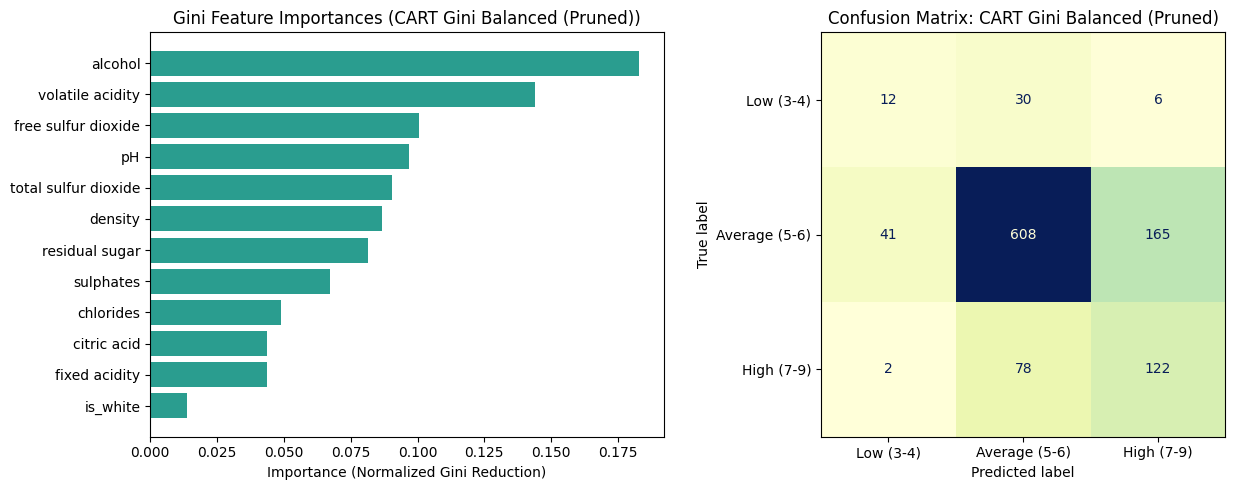

In [25]:
# Cell 23: Visualize Gini feature importances and confusion matrix for the top CART model
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

fi_plot = fi_table.iloc[::-1]
axes[0].barh(fi_plot["feature"], fi_plot["gini_importance"], color="#2a9d8f")
axes[0].set_title(f"Gini Feature Importances ({best_cart_name})")
axes[0].set_xlabel("Importance (Normalized Gini Reduction)")

cm = confusion_matrix(y_test, best_preds, labels=tier_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=tier_order)
disp.plot(ax=axes[1], cmap="YlGnBu", colorbar=False)
axes[1].set_title(f"Confusion Matrix: {best_cart_name}")

plt.tight_layout()
plt.show()

In [26]:
# Cell 24: Prepare stratified train/test splits, class weights, and ensemble classifiers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


def to_quality_tier(q):
  if q <= 4:
    return "Low (3-4)"
  elif q <= 6:
    return "Average (5-6)"
  else:
    return "High (7-9)"


df_ens = df.drop_duplicates().reset_index(drop=True)
df_ens["is_white"] = (df_ens["wine_type"] == "white").astype(int)
df_ens["quality_tier"] = df_ens["quality"].apply(to_quality_tier)

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
tier_order = ["Low (3-4)", "Average (5-6)", "High (7-9)"]
tier_to_int = {t: i for i, t in enumerate(tier_order)}
strat_key = df_ens["wine_type"] + "_" + df_ens["quality_tier"]

X_train, X_test, y_train_str, y_test_str = train_test_split(
    df_ens[feature_cols],
    df_ens["quality_tier"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)

y_train = y_train_str.map(tier_to_int).values
y_test = y_test_str.map(tier_to_int).values

# Balanced sample weights for boosting estimators that take sample_weight
cls_counts = np.bincount(y_train)
cls_weights = {
    c: len(y_train) / (len(cls_counts) * cnt) for c, cnt in enumerate(cls_counts)
}
sample_w_train = np.array([cls_weights[c] for c in y_train])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_bal = RandomForestClassifier(
    n_estimators=250,
    max_depth=14,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
et_bal = ExtraTreesClassifier(
    n_estimators=250,
    max_depth=16,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
hgb_bal = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.06,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    random_state=42,
)
gb_std = GradientBoostingClassifier(
    n_estimators=150, learning_rate=0.06, max_depth=4, random_state=42
)

voting_soft = VotingClassifier(
    estimators=[
        (
            "rf",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=14,
                min_samples_leaf=3,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1,
            ),
        ),
        (
            "et",
            ExtraTreesClassifier(
                n_estimators=200,
                max_depth=16,
                min_samples_leaf=3,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1,
            ),
        ),
        (
            "svm",
            Pipeline([
                ("sc", StandardScaler()),
                (
                    "svc",
                    SVC(
                        C=2.0,
                        kernel="rbf",
                        class_weight="balanced",
                        probability=True,
                        random_state=42,
                    ),
                ),
            ]),
        ),
    ],
    voting="soft",
    weights=[2, 1, 2],
)

stacking_clf = StackingClassifier(
    estimators=[
        (
            "rf",
            RandomForestClassifier(
                n_estimators=150,
                max_depth=12,
                min_samples_leaf=3,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1,
            ),
        ),
        (
            "et",
            ExtraTreesClassifier(
                n_estimators=150,
                max_depth=14,
                min_samples_leaf=3,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1,
            ),
        ),
        (
            "svm",
            Pipeline([
                ("sc", StandardScaler()),
                (
                    "svc",
                    SVC(
                        C=2.0,
                        kernel="rbf",
                        class_weight="balanced",
                        probability=True,
                        random_state=42,
                    ),
                ),
            ]),
        ),
    ],
    final_estimator=LogisticRegression(max_iter=500, random_state=42),
    cv=3,
)

ensemble_models = {
    "Random Forest (Balanced)": (rf_bal, False),
    "Extra Trees (Balanced)": (et_bal, False),
    "HistGradientBoosting (Sample-Weighted)": (hgb_bal, True),
    "Gradient Boosting (Standard)": (gb_std, False),
    "Soft Voting (RF + ET + RBF-SVM)": (voting_soft, False),
    "Stacking (RF + ET + RBF-SVM -> LogReg)": (stacking_clf, False),
}

In [27]:
# Cell 25: Evaluate all ensemble models, print report for top Macro-F1 model, and rank features
summary_rows = []
fitted_results = {}

for name, (est, use_sw) in ensemble_models.items():
  if use_sw:
    cv_scores = []
    for tr_idx, va_idx in skf.split(X_train, y_train):
      m_cv = HistGradientBoostingClassifier(
          max_iter=200,
          learning_rate=0.06,
          max_leaf_nodes=31,
          min_samples_leaf=20,
          random_state=42,
      )
      m_cv.fit(
          X_train.iloc[tr_idx],
          y_train[tr_idx],
          sample_weight=sample_w_train[tr_idx],
      )
      cv_scores.append(
          f1_score(
              y_train[va_idx],
              m_cv.predict(X_train.iloc[va_idx]),
              average="macro",
          )
      )
    cv_mf1 = float(np.mean(cv_scores))
    est.fit(X_train, y_train, sample_weight=sample_w_train)
  else:
    cv_mf1 = float(
        cross_val_score(est, X_train, y_train, cv=skf, scoring="f1_macro").mean()
    )
    est.fit(X_train, y_train)

  train_acc = float(accuracy_score(y_train, est.predict(X_train)))
  test_pred = est.predict(X_test)
  test_acc = float(accuracy_score(y_test, test_pred))
  test_mf1 = float(f1_score(y_test, test_pred, average="macro"))
  test_wf1 = float(f1_score(y_test, test_pred, average="weighted"))
  fitted_results[name] = (est, test_pred)

  summary_rows.append({
      "model": name,
      "cv_macro_f1": round(cv_mf1, 4),
      "train_acc": round(train_acc, 4),
      "test_acc": round(test_acc, 4),
      "test_macro_f1": round(test_mf1, 4),
      "test_weighted_f1": round(test_wf1, 4),
  })

ensemble_summary = pd.DataFrame(summary_rows).sort_values(
    "test_macro_f1", ascending=False
)
display(ensemble_summary)

best_ens_name = ensemble_summary.iloc[0]["model"]
best_ens_model, best_ens_pred = fitted_results[best_ens_name]

print(f"\n=== Classification Report: {best_ens_name} ===")
print(
    classification_report(
        y_test, best_ens_pred, labels=[0, 1, 2], target_names=tier_order, digits=4
    )
)

rf_bal.fit(X_train, y_train)
rf_importance_df = pd.DataFrame({
    "feature": feature_cols,
    "rf_importance": rf_bal.feature_importances_,
}).sort_values("rf_importance", ascending=False)
print("=== Random Forest (Balanced) Feature Importances ===")
display(rf_importance_df.round(4))

,model,cv_macro_f1,train_acc,test_acc,test_macro_f1,test_weighted_f1
1,Extra Trees (Balanced),0.5575,0.8484,0.7359,0.6176,0.7512
2,HistGradientBoosting (Sample-Weighted),0.5324,0.9901,0.7744,0.5643,0.7716
0,Random Forest (Balanced),0.5190,0.9481,0.7885,0.5256,0.7759
4,Soft Voting (RF + ET + RBF-SVM),0.4915,0.8969,0.7979,0.4971,0.7790
3,Gradient Boosting (Standard),0.4907,0.8804,0.8036,0.4960,0.7742
5,Stacking (RF + ET + RBF-SVM -> LogReg),0.4800,0.8912,0.8083,0.4862,0.7790



=== Classification Report: Extra Trees (Balanced) ===
               precision    recall  f1-score   support

    Low (3-4)     0.5122    0.4375    0.4719        48
Average (5-6)     0.8940    0.7457    0.8131       814
   High (7-9)     0.4506    0.7673    0.5678       202

     accuracy                         0.7359      1064
    macro avg     0.6189    0.6502    0.6176      1064
 weighted avg     0.7926    0.7359    0.7512      1064

=== Random Forest (Balanced) Feature Importances ===


,feature,rf_importance
10,alcohol,0.1422
5,free sulfur dioxide,0.1101
1,volatile acidity,0.1092
7,density,0.0995
6,total sulfur dioxide,0.0903
4,chlorides,0.0802
2,citric acid,0.0796
9,sulphates,0.0756
3,residual sugar,0.0727
8,pH,0.0696


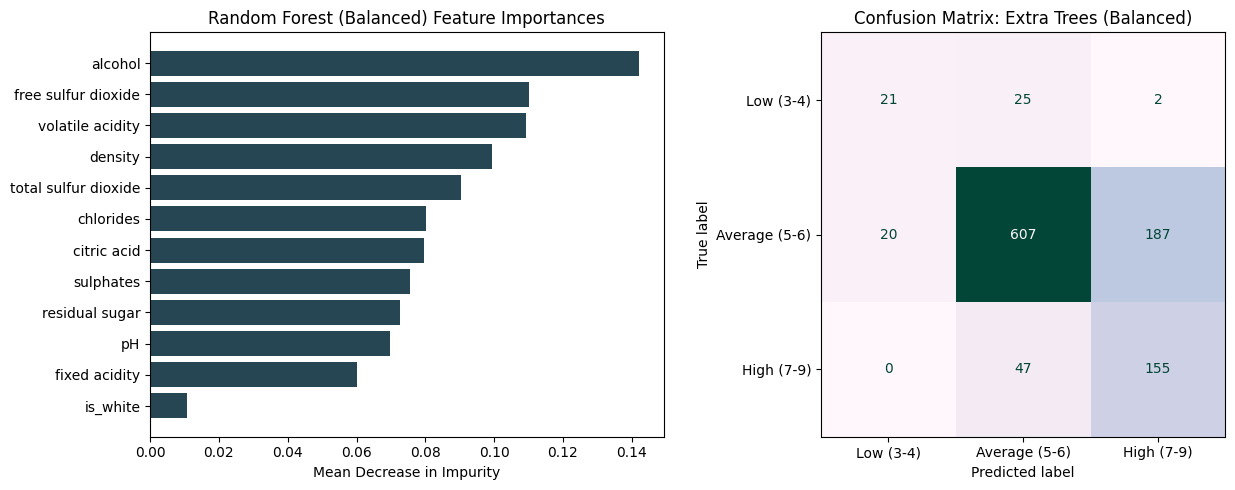

In [28]:
# Cell 26: Visualize Random Forest feature importances and best ensemble confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

fi_plot = rf_importance_df.iloc[::-1]
axes[0].barh(fi_plot["feature"], fi_plot["rf_importance"], color="#264653")
axes[0].set_title("Random Forest (Balanced) Feature Importances")
axes[0].set_xlabel("Mean Decrease in Impurity")

cm = confusion_matrix(y_test, best_ens_pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=tier_order)
disp.plot(ax=axes[1], cmap="PuBuGn", colorbar=False)
axes[1].set_title(f"Confusion Matrix: {best_ens_name}")

plt.tight_layout()
plt.show()

In [29]:
# Cell 27: Logistic Regression for wine quality tier classification
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def to_tier_id(q):
  if q <= 4:
    return 0
  elif q <= 6:
    return 1
  else:
    return 2


df_clf = df.drop_duplicates().reset_index(drop=True)
df_clf["is_white"] = (df_clf["wine_type"] == "white").astype(int)
df_clf["tier_id"] = df_clf["quality"].apply(to_tier_id)

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
tier_names = ["Low (3-4)", "Average (5-6)", "High (7-9)"]
strat_key = df_clf["wine_type"] + "_" + df_clf["tier_id"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    df_clf[feature_cols],
    df_clf["tier_id"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg_pipe = Pipeline([
    ("scaler", StandardScaler()),
    (
        "clf",
        LogisticRegression(
            C=1.0, max_iter=1000, class_weight="balanced", random_state=42
        ),
    ),
])

cv_f1 = cross_val_score(logreg_pipe, X_train, y_train, cv=skf, scoring="f1_macro")
logreg_pipe.fit(X_train, y_train)
y_pred_lr = logreg_pipe.predict(X_test)

print(
    f"Logistic Regression | 5-Fold CV Macro-F1: {cv_f1.mean():.4f} | Test"
    f" Accuracy: {accuracy_score(y_test, y_pred_lr):.4f} | Test Macro-F1:"
    f" {f1_score(y_test, y_pred_lr, average='macro'):.4f}"
)
print(
    classification_report(
        y_test, y_pred_lr, labels=[0, 1, 2], target_names=tier_names, digits=4
    )
)

Logistic Regression | 5-Fold CV Macro-F1: 0.4634 | Test Accuracy: 0.5555 | Test Macro-F1: 0.4693
               precision    recall  f1-score   support

    Low (3-4)     0.1498    0.7083    0.2473        48
Average (5-6)     0.9034    0.4939    0.6386       814
   High (7-9)     0.3954    0.7673    0.5219       202

     accuracy                         0.5555      1064
    macro avg     0.4829    0.6565    0.4693      1064
 weighted avg     0.7729    0.5555    0.5988      1064



In [30]:
# Cell 28: Rule-based Decision Tree classifier for wine quality tiers
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.tree import DecisionTreeClassifier, export_text

dt_clf = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=42,
)

dt_cv_f1 = cross_val_score(dt_clf, X_train, y_train, cv=skf, scoring="f1_macro")
dt_clf.fit(X_train, y_train)
y_pred_dt = dt_clf.predict(X_test)

print(
    f"Decision Tree | 5-Fold CV Macro-F1: {dt_cv_f1.mean():.4f} | Test Accuracy:"
    f" {accuracy_score(y_test, y_pred_dt):.4f} | Test Macro-F1:"
    f" {f1_score(y_test, y_pred_dt, average='macro'):.4f}"
)
print(
    classification_report(
        y_test, y_pred_dt, labels=[0, 1, 2], target_names=tier_names, digits=4
    )
)
print("--- Top Rule Branches (max_depth=3 preview) ---")
dt_preview = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=42,
).fit(X_train, y_train)
print(export_text(dt_preview, feature_names=feature_cols))

Decision Tree | 5-Fold CV Macro-F1: 0.4468 | Test Accuracy: 0.5630 | Test Macro-F1: 0.4604
               precision    recall  f1-score   support

    Low (3-4)     0.1453    0.5417    0.2291        48
Average (5-6)     0.8824    0.5160    0.6512       814
   High (7-9)     0.3741    0.7574    0.5008       202

     accuracy                         0.5630      1064
    macro avg     0.4672    0.6050    0.4604      1064
 weighted avg     0.7526    0.5630    0.6036      1064

--- Top Rule Branches (max_depth=3 preview) ---
|--- alcohol <= 10.62
|   |--- free sulfur dioxide <= 17.50
|   |   |--- sulphates <= 0.63
|   |   |   |--- class: 0
|   |   |--- sulphates >  0.63
|   |   |   |--- class: 1
|   |--- free sulfur dioxide >  17.50
|   |   |--- volatile acidity <= 0.25
|   |   |   |--- class: 1
|   |   |--- volatile acidity >  0.25
|   |   |   |--- class: 1
|--- alcohol >  10.62
|   |--- free sulfur dioxide <= 11.50
|   |   |--- sulphates <= 0.64
|   |   |   |--- class: 0
|   |   |--- sul

In [31]:
# Cell 29: Hyperparameter-tuned Random Forest classifier via RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import RandomizedSearchCV

rf_estimator = RandomForestClassifier(
    class_weight="balanced", random_state=42, n_jobs=-1
)

rf_param_distributions = {
    "n_estimators": [150, 250, 400],
    "max_depth": [8, 12, 16, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
}

rf_search = RandomizedSearchCV(
    estimator=rf_estimator,
    param_distributions=rf_param_distributions,
    n_iter=15,
    scoring="f1_macro",
    cv=skf,
    random_state=42,
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)

print("Best Random Forest Params:", rf_search.best_params_)
print(
    f"Optimized RF | Best CV Macro-F1: {rf_search.best_score_:.4f} | Test"
    f" Accuracy: {accuracy_score(y_test, y_pred_rf):.4f} | Test Macro-F1:"
    f" {f1_score(y_test, y_pred_rf, average='macro'):.4f}"
)
print(
    classification_report(
        y_test, y_pred_rf, labels=[0, 1, 2], target_names=tier_names, digits=4
    )
)

Best Random Forest Params: {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 12}
Optimized RF | Best CV Macro-F1: 0.5465 | Test Accuracy: 0.7763 | Test Macro-F1: 0.5888
               precision    recall  f1-score   support

    Low (3-4)     0.5500    0.2292    0.3235        48
Average (5-6)     0.8765    0.8280    0.8515       814
   High (7-9)     0.5127    0.6980    0.5912       202

     accuracy                         0.7763      1064
    macro avg     0.6464    0.5851    0.5888      1064
 weighted avg     0.7927    0.7763    0.7783      1064



In [48]:
# Cell 30: XGBoost classifier (with HistGradientBoostingClassifier fallback if xgboost is not installed)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
import numpy as np

cls_counts = np.bincount(y_train)
cls_weights = {
    c: len(y_train) / (len(cls_counts) * cnt) for c, cnt in enumerate(cls_counts)
}
sample_weights = np.array([cls_weights[c] for c in y_train])

# Convert y_train to a numpy array for positional indexing
y_train_arr = y_train.to_numpy()

try:
  from xgboost import XGBClassifier

  xgb_model = XGBClassifier(
      n_estimators=250,
      learning_rate=0.06,
      max_depth=5,
      subsample=0.85,
      colsample_bytree=0.85,
      eval_metric="mlogloss",
      random_state=42,
      n_jobs=-1,
  )
  cv_scores_xgb = []
  for tr_idx, va_idx in skf.split(X_train, y_train):
    m_fold = XGBClassifier(
        n_estimators=250,
        learning_rate=0.06,
        max_depth=5,
        subsample=0.85,
        colsample_bytree=0.85,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1,
    )
    m_fold.fit(
        X_train.iloc[tr_idx],
        y_train_arr[tr_idx],
        sample_weight=sample_weights[tr_idx],
    )
    cv_scores_xgb.append(
        f1_score(
            y_train_arr[va_idx], m_fold.predict(X_train.iloc[va_idx]), average="macro"
        )
    )

  xgb_model.fit(X_train, y_train, sample_weight=sample_weights)
  y_pred_gb = xgb_model.predict(X_test)
  gb_label = f"XGBoost | 5-Fold CV Macro-F1: {np.mean(cv_scores_xgb):.4f}"
except ImportError:
  hgb_model = HistGradientBoostingClassifier(
      max_iter=200,
      learning_rate=0.06,
      max_leaf_nodes=31,
      min_samples_leaf=20,
      random_state=42,
  )
  cv_scores_hgb = []
  for tr_idx, va_idx in skf.split(X_train, y_train):
    m_fold = HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.06,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        random_state=42,
    )
    m_fold.fit(
        X_train.iloc[tr_idx],
        y_train_arr[tr_idx],
        sample_weight=sample_weights[tr_idx],
    )
    cv_scores_hgb.append(
        f1_score(
            y_train_arr[va_idx], m_fold.predict(X_train.iloc[va_idx]), average="macro"
        )
    )

  hgb_model.fit(X_train, y_train, sample_weight=sample_weights)
  y_pred_gb = hgb_model.predict(X_test)
  gb_label = (
      "HistGradientBoosting (XGBoost fallback) | 5-Fold CV Macro-F1:"
      f" {np.mean(cv_scores_hgb):.4f}"
  )

print(
    f"{gb_label} | Test Accuracy: {accuracy_score(y_test, y_pred_gb):.4f} |"
    f" Test Macro-F1: {f1_score(y_test, y_pred_gb, average='macro'):.4f}"
)
print(
    classification_report(
        y_test, y_pred_gb, labels=[0, 1, 2], target_names=tier_names, digits=4
    )
)

XGBoost | 5-Fold CV Macro-F1: 0.5480 | Test Accuracy: 0.7293 | Test Macro-F1: 0.5642
               precision    recall  f1-score   support

    Low (3-4)     0.3061    0.3125    0.3093        48
Average (5-6)     0.8817    0.7506    0.8109       814
   High (7-9)     0.4658    0.7426    0.5725       202

     accuracy                         0.7293      1064
    macro avg     0.5512    0.6019    0.5642      1064
 weighted avg     0.7768    0.7293    0.7430      1064



In [33]:
# Cell 31: Similarity-based K-Nearest Neighbors classifier with k tuning on CV Macro-F1
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.neighbors import KNeighborsClassifier

best_k = 3
best_k_cv = -1.0

for k_cand in [3, 5, 7, 11, 15]:
  knn_cand = Pipeline([
      ("scaler", StandardScaler()),
      ("knn", KNeighborsClassifier(n_neighbors=k_cand, weights="distance")),
  ])
  score_k = cross_val_score(
      knn_cand, X_train, y_train, cv=skf, scoring="f1_macro"
  ).mean()
  if score_k > best_k_cv:
    best_k_cv = float(score_k)
    best_k = k_cand

knn_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k, weights="distance")),
])
knn_pipe.fit(X_train, y_train)
y_pred_knn = knn_pipe.predict(X_test)

print(
    f"KNN (k={best_k}) | 5-Fold CV Macro-F1: {best_k_cv:.4f} | Test Accuracy:"
    f" {accuracy_score(y_test, y_pred_knn):.4f} | Test Macro-F1:"
    f" {f1_score(y_test, y_pred_knn, average='macro'):.4f}"
)
print(
    classification_report(
        y_test, y_pred_knn, labels=[0, 1, 2], target_names=tier_names, digits=4
    )
)

KNN (k=3) | 5-Fold CV Macro-F1: 0.5166 | Test Accuracy: 0.7923 | Test Macro-F1: 0.5523
               precision    recall  f1-score   support

    Low (3-4)     0.3636    0.1667    0.2286        48
Average (5-6)     0.8483    0.8931    0.8701       814
   High (7-9)     0.5838    0.5347    0.5581       202

     accuracy                         0.7923      1064
    macro avg     0.5986    0.5315    0.5523      1064
 weighted avg     0.7762    0.7923    0.7820      1064



In [34]:
# Cell 32: Probabilistic Gaussian Naive Bayes classifier for wine quality tiers
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.naive_bayes import GaussianNB

nb_pipe = Pipeline([("scaler", StandardScaler()), ("nb", GaussianNB())])

nb_cv_f1 = cross_val_score(nb_pipe, X_train, y_train, cv=skf, scoring="f1_macro")
nb_pipe.fit(X_train, y_train)
y_pred_nb = nb_pipe.predict(X_test)

print(
    f"Gaussian Naive Bayes | 5-Fold CV Macro-F1: {nb_cv_f1.mean():.4f} | Test"
    f" Accuracy: {accuracy_score(y_test, y_pred_nb):.4f} | Test Macro-F1:"
    f" {f1_score(y_test, y_pred_nb, average='macro'):.4f}"
)
print(
    classification_report(
        y_test, y_pred_nb, labels=[0, 1, 2], target_names=tier_names, digits=4
    )
)

Gaussian Naive Bayes | 5-Fold CV Macro-F1: 0.4852 | Test Accuracy: 0.7002 | Test Macro-F1: 0.5085
               precision    recall  f1-score   support

    Low (3-4)     0.2571    0.1875    0.2169        48
Average (5-6)     0.8627    0.7334    0.7928       814
   High (7-9)     0.4125    0.6881    0.5158       202

     accuracy                         0.7002      1064
    macro avg     0.5108    0.5363    0.5085      1064
 weighted avg     0.7499    0.7002    0.7142      1064



In [35]:
# Cell 33: Multi-Layer Perceptron (MLP) classifier for nonlinear quality tier prediction
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def to_tier_id(q):
  if q <= 4:
    return 0
  elif q <= 6:
    return 1
  else:
    return 2


df_work = df.drop_duplicates().reset_index(drop=True)
df_work["is_white"] = (df_work["wine_type"] == "white").astype(int)
df_work["tier_id"] = df_work["quality"].apply(to_tier_id)

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
tier_names = ["Low (3-4)", "Average (5-6)", "High (7-9)"]
strat_key = df_work["wine_type"] + "_" + df_work["tier_id"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    df_work[feature_cols],
    df_work["tier_id"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mlp_pipe = Pipeline([
    ("scaler", StandardScaler()),
    (
        "mlp",
        MLPClassifier(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            alpha=1e-3,
            max_iter=400,
            early_stopping=True,
            random_state=42,
        ),
    ),
])

mlp_cv = cross_val_score(mlp_pipe, X_train, y_train, cv=skf, scoring="f1_macro")
mlp_pipe.fit(X_train, y_train)
y_pred_mlp = mlp_pipe.predict(X_test)

print(
    f"MLP Classifier | 5-Fold CV Macro-F1: {mlp_cv.mean():.4f} | Test"
    f" Accuracy: {accuracy_score(y_test, y_pred_mlp):.4f} | Test Macro-F1:"
    f" {f1_score(y_test, y_pred_mlp, average='macro'):.4f}"
)
print(
    classification_report(
        y_test, y_pred_mlp, labels=[0, 1, 2], target_names=tier_names, digits=4
    )
)

MLP Classifier | 5-Fold CV Macro-F1: 0.4312 | Test Accuracy: 0.7998 | Test Macro-F1: 0.4449
               precision    recall  f1-score   support

    Low (3-4)     0.0000    0.0000    0.0000        48
Average (5-6)     0.8129    0.9607    0.8806       814
   High (7-9)     0.6765    0.3416    0.4539       202

     accuracy                         0.7998      1064
    macro avg     0.4965    0.4341    0.4449      1064
 weighted avg     0.7503    0.7998    0.7599      1064



In [36]:
# Cell 34: Extra Trees ensemble classifier with class balancing for quality tiers
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score

et_clf = ExtraTreesClassifier(
    n_estimators=250,
    max_depth=16,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

et_cv = cross_val_score(et_clf, X_train, y_train, cv=skf, scoring="f1_macro")
et_clf.fit(X_train, y_train)
y_pred_et = et_clf.predict(X_test)

print(
    f"Extra Trees | 5-Fold CV Macro-F1: {et_cv.mean():.4f} | Test Accuracy:"
    f" {accuracy_score(y_test, y_pred_et):.4f} | Test Macro-F1:"
    f" {f1_score(y_test, y_pred_et, average='macro'):.4f}"
)
print(
    classification_report(
        y_test, y_pred_et, labels=[0, 1, 2], target_names=tier_names, digits=4
    )
)

Extra Trees | 5-Fold CV Macro-F1: 0.5604 | Test Accuracy: 0.7284 | Test Macro-F1: 0.5991
               precision    recall  f1-score   support

    Low (3-4)     0.4167    0.4167    0.4167        48
Average (5-6)     0.8976    0.7322    0.8065       814
   High (7-9)     0.4517    0.7871    0.5740       202

     accuracy                         0.7284      1064
    macro avg     0.5887    0.6453    0.5991      1064
 weighted avg     0.7912    0.7284    0.7448      1064



In [39]:
# Cell 35: Discover chemical correlations, tier patterns, and red vs. white contrasts (no plots)
chem_cols = [c for c in feature_cols if c != "is_white"]

# Ensure quality_tier exists in df_work
if "quality_tier" not in df_work.columns:
    df_work["quality_tier"] = df_work["quality"].apply(to_quality_tier)

print("--- Pearson Correlation of Chemical Features with Quality (Deduplicated) ---")
q_corr = (
    df_work[chem_cols + ["quality"]]
    .corr()["quality"]
    .drop("quality")
    .sort_values(key=abs, ascending=False)
)
display(q_corr.round(4))

print("--- Mean Chemical Profile by Quality Tier ---")
display(df_work.groupby("quality_tier")[chem_cols].mean().round(4))

print("--- Mean Quality & Tier Share by Wine Type ---")
display(
    df_work.groupby("wine_type")["quality"].agg(
        ["count", "mean", "median", "std"]
    ).round(4)
)
display(
    (
        pd.crosstab(df_work["wine_type"], df_work["quality_tier"], normalize="index")
        * 100
    ).round(2)
)

--- Pearson Correlation of Chemical Features with Quality (Deduplicated) ---


,quality
alcohol,0.4694
density,-0.3264
volatile acidity,-0.2652
chlorides,-0.2021
citric acid,0.0980
fixed acidity,-0.0801
residual sugar,-0.0568
free sulfur dioxide,0.0540
total sulfur dioxide,-0.0503
sulphates,0.0419


--- Mean Chemical Profile by Quality Tier ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality_tier,,,,,,,,,,,
Average (5-6),7.2396,0.3493,0.3166,5.2945,0.0594,30.3564,116.6428,0.9950,3.2199,0.5320,10.3151
High (7-9),7.0792,0.2939,0.3369,4.2591,0.0444,30.4534,106.2111,0.9927,3.2407,0.5447,11.5732
Low (3-4),7.3742,0.4693,0.2727,4.1754,0.0626,22.7331,104.1250,0.9949,3.2386,0.5073,10.2150


--- Mean Quality & Tier Share by Wine Type ---


,count,mean,median,std
wine_type,,,,
red,1359,5.6233,6.0,0.8236
white,3961,5.8548,6.0,0.8907


quality_tier,Average (5-6),High (7-9),Low (3-4)
wine_type,,,
red,81.82,13.54,4.64
white,74.80,20.83,4.37


In [40]:
# Cell 36: Rank features via Mutual Information & Extra Trees importance, then test top subset
from sklearn.feature_selection import SelectFromModel, mutual_info_classif

mi_scores = mutual_info_classif(X_train, y_train, random_state=42)
fs_ranking = pd.DataFrame({
    "feature": feature_cols,
    "mutual_info": mi_scores,
    "extra_trees_importance": et_clf.feature_importances_,
}).sort_values("extra_trees_importance", ascending=False)

display(fs_ranking.round(4))

selector = SelectFromModel(et_clf, threshold="median")
X_train_sel = selector.fit_transform(X_train, y_train)
X_test_sel = selector.transform(X_test)
selected_feats = [
    f for f, keep in zip(feature_cols, selector.get_support()) if keep
]

et_selected = ExtraTreesClassifier(
    n_estimators=250,
    max_depth=16,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
et_selected.fit(X_train_sel, y_train)
y_pred_sel = et_selected.predict(X_test_sel)

print(f"Selected {len(selected_feats)} features (> median importance): {selected_feats}")
print(
    f"Selected-Feature Extra Trees | Test Accuracy:"
    f" {accuracy_score(y_test, y_pred_sel):.4f} | Test Macro-F1:"
    f" {f1_score(y_test, y_pred_sel, average='macro'):.4f}"
)

,feature,mutual_info,extra_trees_importance
10,alcohol,0.0881,0.1987
5,free sulfur dioxide,0.0197,0.1295
1,volatile acidity,0.0255,0.1199
6,total sulfur dioxide,0.0212,0.0804
7,density,0.0519,0.0799
2,citric acid,0.0257,0.0710
9,sulphates,0.0122,0.0625
8,pH,0.0084,0.0594
3,residual sugar,0.0250,0.0578
4,chlorides,0.0297,0.0572


Selected 6 features (> median importance): ['volatile acidity', 'citric acid', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'alcohol']
Selected-Feature Extra Trees | Test Accuracy: 0.6908 | Test Macro-F1: 0.5452


In [41]:
# Cell 37: Create domain-driven wine chemistry ratios/differences and evaluate impact
def engineer_wine_features(data):
  out = data.copy()
  out["bound_sulfur_dioxide"] = np.maximum(
      out["total sulfur dioxide"] - out["free sulfur dioxide"], 0.0
  )
  out["free_to_total_so2_ratio"] = out["free sulfur dioxide"] / (
      out["total sulfur dioxide"] + 1e-5
  )
  out["volatile_to_fixed_acidity"] = out["volatile acidity"] / (
      out["fixed acidity"] + 1e-5
  )
  out["sugar_to_alcohol_ratio"] = out["residual sugar"] / (
      out["alcohol"] + 1e-5
  )
  out["sulphate_to_chloride_ratio"] = out["sulphates"] / (
      out["chlorides"] + 1e-5
  )
  return out


df_eng = engineer_wine_features(df_work)
engineered_cols = feature_cols + [
    "bound_sulfur_dioxide",
    "free_to_total_so2_ratio",
    "volatile_to_fixed_acidity",
    "sugar_to_alcohol_ratio",
    "sulphate_to_chloride_ratio",
]

X_tr_eng, X_te_eng, y_tr_eng, y_te_eng = train_test_split(
    df_eng[engineered_cols],
    df_eng["tier_id"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)

et_eng = ExtraTreesClassifier(
    n_estimators=250,
    max_depth=16,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
et_eng_cv = cross_val_score(
    et_eng, X_tr_eng, y_tr_eng, cv=skf, scoring="f1_macro"
)
et_eng.fit(X_tr_eng, y_tr_eng)
y_pred_eng = et_eng.predict(X_te_eng)

print("Added features:", engineered_cols[len(feature_cols) :])
print(
    f"Engineered Extra Trees | 5-Fold CV Macro-F1: {et_eng_cv.mean():.4f} |"
    f" Test Accuracy: {accuracy_score(y_te_eng, y_pred_eng):.4f} | Test"
    f" Macro-F1: {f1_score(y_te_eng, y_pred_eng, average='macro'):.4f}"
)

Added features: ['bound_sulfur_dioxide', 'free_to_total_so2_ratio', 'volatile_to_fixed_acidity', 'sugar_to_alcohol_ratio', 'sulphate_to_chloride_ratio']
Engineered Extra Trees | 5-Fold CV Macro-F1: 0.5747 | Test Accuracy: 0.7491 | Test Macro-F1: 0.6016


In [42]:
# Cell 38: Compute Pearson correlations with quality and strongest inter-feature relationships
import numpy as np
import pandas as pd

df_ana = df.drop_duplicates().reset_index(drop=True)
df_ana["is_white"] = (df_ana["wine_type"] == "white").astype(int)

chem_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
]

corr_matrix = df_ana[chem_cols + ["quality"]].corr()

print("--- Correlations with Quality (Sorted by Magnitude) ---")
quality_corr = (
    corr_matrix["quality"]
    .drop("quality")
    .sort_values(key=abs, ascending=False)
)
display(quality_corr.round(4))

pair_rows = []
for i in range(len(chem_cols)):
  for j in range(i + 1, len(chem_cols)):
    c1, c2 = chem_cols[i], chem_cols[j]
    r_val = corr_matrix.loc[c1, c2]
    pair_rows.append({
        "feature_1": c1,
        "feature_2": c2,
        "pearson_r": round(float(r_val), 4),
        "abs_r": round(float(abs(r_val)), 4),
    })

strong_pairs = (
    pd.DataFrame(pair_rows)
    .sort_values("abs_r", ascending=False)
    .drop(columns=["abs_r"])
    .head(8)
)
print("--- Strongest Inter-Feature Correlations ---")
display(strong_pairs)

--- Correlations with Quality (Sorted by Magnitude) ---


,quality
alcohol,0.4694
density,-0.3264
volatile acidity,-0.2652
chlorides,-0.2021
citric acid,0.0980
fixed acidity,-0.0801
residual sugar,-0.0568
free sulfur dioxide,0.0540
total sulfur dioxide,-0.0503
sulphates,0.0419


--- Strongest Inter-Feature Correlations ---


,feature_1,feature_2,pearson_r
40,free sulfur dioxide,total sulfur dioxide,0.7205
51,density,alcohol,-0.6678
30,residual sugar,density,0.5209
29,residual sugar,total sulfur dioxide,0.4875
6,fixed acidity,density,0.4782
38,chlorides,sulphates,0.4051
14,volatile acidity,total sulfur dioxide,-0.4007
28,residual sugar,free sulfur dioxide,0.3987


In [43]:
# Cell 39: Detect multivariate anomalies in standardized chemical space using Isolation Forest
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_chem_scaled = scaler.fit_transform(df_ana[chem_cols])

iso_forest = IsolationForest(
    n_estimators=200, contamination=0.03, random_state=42, n_jobs=-1
)
iso_labels = iso_forest.fit_predict(X_chem_scaled)  # -1 = outlier, 1 = inlier
anomaly_scores = iso_forest.decision_function(X_chem_scaled)

df_ana["iso_label"] = iso_labels
df_ana["anomaly_score"] = anomaly_scores

n_outliers = int((iso_labels == -1).sum())
print(
    f"Flagged outliers: {n_outliers} / {len(df_ana)}"
    f" ({n_outliers / len(df_ana) * 100:.2f}%)"
)
print(
    "Mean quality -> Inliers:"
    f" {df_ana.loc[iso_labels == 1, 'quality'].mean():.4f} | Outliers:"
    f" {df_ana.loc[iso_labels == -1, 'quality'].mean():.4f}"
)
print(
    "Red wine share among outliers:"
    f" {(df_ana.loc[iso_labels == -1, 'wine_type'] == 'red').mean() * 100:.2f}%"
)

print("\n--- Top 5 Most Anomalous Wine Samples (Lowest Decision Score) ---")
cols_show = [
    "wine_type",
    "quality",
    "alcohol",
    "residual sugar",
    "volatile acidity",
    "total sulfur dioxide",
    "anomaly_score",
]
display(df_ana.nsmallest(5, "anomaly_score")[cols_show].round(4))

Flagged outliers: 160 / 5320 (3.01%)
Mean quality -> Inliers: 5.8047 | Outliers: 5.5062
Red wine share among outliers: 70.00%

--- Top 5 Most Anomalous Wine Samples (Lowest Decision Score) ---


,wine_type,quality,alcohol,residual sugar,volatile acidity,total sulfur dioxide,anomaly_score
135,red,4,9.4,3.4,0.520,69.0,-0.1293
1123,red,6,9.1,1.7,0.760,64.0,-0.1079
3653,white,6,11.7,65.8,0.965,160.0,-0.1058
385,red,7,11.2,3.7,0.685,43.0,-0.0893
308,red,5,13.0,4.8,0.530,77.0,-0.0834


In [44]:
# Cell 40: Compute 2D t-SNE embedding on a 1,500-row subset and summarize cluster structure (no image)
from sklearn.manifold import TSNE

rng = np.random.default_rng(42)
sub_idx = np.sort(rng.choice(len(df_ana), size=1500, replace=False))

# Uses n_iter for compatibility across scikit-learn versions
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    n_iter=1000,
    random_state=42,
)
X_tsne = tsne.fit_transform(X_chem_scaled[sub_idx])

tsne_df = pd.DataFrame({
    "tsne_1": X_tsne[:, 0],
    "tsne_2": X_tsne[:, 1],
    "wine_type": df_ana.iloc[sub_idx]["wine_type"].values,
    "quality": df_ana.iloc[sub_idx]["quality"].values,
})

print(
    f"t-SNE embedding shape: {X_tsne.shape} | Final KL divergence:"
    f" {tsne.kl_divergence_:.4f}"
)
print("\n--- Mean t-SNE Coordinates by Wine Type ---")
display(tsne_df.groupby("wine_type")[["tsne_1", "tsne_2"]].mean().round(4))
print("\n--- Mean t-SNE Coordinates by Quality Score ---")
display(tsne_df.groupby("quality")[["tsne_1", "tsne_2"]].mean().round(4))

t-SNE embedding shape: (1500, 2) | Final KL divergence: 1.1943

--- Mean t-SNE Coordinates by Wine Type ---


,tsne_1,tsne_2
wine_type,,
red,-32.8200,14.0713
white,9.6343,-6.5541



--- Mean t-SNE Coordinates by Quality Score ---


,tsne_1,tsne_2
quality,,
3,-8.0483,-3.7811
4,-10.9064,-1.5067
5,-3.1436,7.2879
6,1.5853,-2.8187
7,-0.7973,-12.1324
8,0.0416,-20.4401
9,-1.4478,-35.7141


In [45]:
# Cell 41: Compute 2D UMAP projection (installs umap-learn if needed) and summarize coordinates (no image)
try:
  import umap
except ImportError:
  import subprocess, sys
  subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
  import umap

reducer = umap.UMAP(
    n_components=2, n_neighbors=25, min_dist=0.1, random_state=42
)
X_umap = reducer.fit_transform(X_chem_scaled[sub_idx])

umap_df = pd.DataFrame({
    "umap_1": X_umap[:, 0],
    "umap_2": X_umap[:, 1],
    "wine_type": df_ana.iloc[sub_idx]["wine_type"].values,
    "quality": df_ana.iloc[sub_idx]["quality"].values,
})

print(f"UMAP embedding shape: {X_umap.shape}")
print("\n--- Mean UMAP Coordinates by Wine Type ---")
display(umap_df.groupby("wine_type")[["umap_1", "umap_2"]].mean().round(4))
print("\n--- Mean UMAP Coordinates by Quality Score ---")
display(umap_df.groupby("quality")[["umap_1", "umap_2"]].mean().round(4))

UMAP embedding shape: (1500, 2)

--- Mean UMAP Coordinates by Wine Type ---


,umap_1,umap_2
wine_type,,
red,2.0448,5.3033
white,11.0705,7.5550



--- Mean UMAP Coordinates by Quality Score ---


,umap_1,umap_2
quality,,
3,9.1130,7.5381
4,8.5255,7.3013
5,8.2626,6.0900
6,9.1140,7.0843
7,8.9450,8.1514
8,10.0306,9.0157
9,10.9477,10.8409


In [46]:
# Cell 42: Systematic hyperparameter sweep for Extra Trees across tree count, depth, and leaf size
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split


def to_tier_id(q):
  if q <= 4:
    return 0
  elif q <= 6:
    return 1
  else:
    return 2


df_tune = df.drop_duplicates().reset_index(drop=True)
df_tune["is_white"] = (df_tune["wine_type"] == "white").astype(int)
df_tune["tier_id"] = df_tune["quality"].apply(to_tier_id)

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
tier_names = ["Low (3-4)", "Average (5-6)", "High (7-9)"]
strat_key = df_tune["wine_type"] + "_" + df_tune["tier_id"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    df_tune[feature_cols],
    df_tune["tier_id"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)
X_tr_arr = X_train.to_numpy()
X_te_arr = X_test.to_numpy()
y_tr_arr = y_train.to_numpy()
y_te_arr = y_test.to_numpy()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

sweep_rows = []
best_sweep_cfg = None
best_sweep_f1 = -1.0

for n_est in [150, 300]:
  for max_d in [12, 18]:
    for min_leaf in [2, 4]:
      clf = ExtraTreesClassifier(
          n_estimators=n_est,
          max_depth=max_d,
          min_samples_leaf=min_leaf,
          class_weight="balanced",
          random_state=42,
          n_jobs=-1,
      )
      fold_f1s = []
      for tr_idx, va_idx in skf.split(X_tr_arr, y_tr_arr):
        clf.fit(X_tr_arr[tr_idx], y_tr_arr[tr_idx])
        preds_va = clf.predict(X_tr_arr[va_idx])
        fold_f1s.append(f1_score(y_tr_arr[va_idx], preds_va, average="macro"))
      mean_f1 = float(np.mean(fold_f1s))
      sweep_rows.append({
          "n_estimators": n_est,
          "max_depth": max_d,
          "min_samples_leaf": min_leaf,
          "cv_macro_f1": round(mean_f1, 4),
      })
      if mean_f1 > best_sweep_f1:
        best_sweep_f1 = mean_f1
        best_sweep_cfg = {
            "n_estimators": n_est,
            "max_depth": max_d,
            "min_samples_leaf": min_leaf,
        }

sweep_df = pd.DataFrame(sweep_rows).sort_values("cv_macro_f1", ascending=False)
display(sweep_df)
print(
    f"Best sweep configuration: {best_sweep_cfg} | 5-Fold CV Macro-F1:"
    f" {best_sweep_f1:.4f}"
)

,n_estimators,max_depth,min_samples_leaf,cv_macro_f1
6,300,18,2,0.5630
3,150,18,4,0.5537
2,150,18,2,0.5506
7,300,18,4,0.5486
4,300,12,2,0.5485
0,150,12,2,0.5451
5,300,12,4,0.5362
1,150,12,4,0.5283


Best sweep configuration: {'n_estimators': 300, 'max_depth': 18, 'min_samples_leaf': 2} | 5-Fold CV Macro-F1: 0.5630


In [49]:
# Cell 43: Compare exhaustive GridSearchCV vs. exploratory RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import ExtraTreesClassifier
import pandas as pd

grid_space = {
    "n_estimators": [150, 250],
    "max_depth": [12, 18],
    "min_samples_leaf": [2, 4],
}

grid_search = GridSearchCV(
    estimator=ExtraTreesClassifier(
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
    param_grid=grid_space,
    scoring="f1_macro",
    cv=skf,
    n_jobs=-1,
)
grid_search.fit(X_tr_arr, y_tr_arr)

# Streamlined search space to prevent timeout / execution interruption
random_space = {
    "n_estimators": [150, 250],
    "max_depth": [14, 18, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [2, 4],
    "max_features": ["sqrt", "log2"],
}

random_search = RandomizedSearchCV(
    estimator=ExtraTreesClassifier(
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
    param_distributions=random_space,
    n_iter=6,
    scoring="f1_macro",
    cv=skf,
    random_state=42,
    n_jobs=-1,
)
random_search.fit(X_tr_arr, y_tr_arr)

gs_test_pred = grid_search.predict(X_te_arr)
rs_test_pred = random_search.predict(X_te_arr)

search_comparison = pd.DataFrame([
    {
        "search_method": "GridSearchCV",
        "best_cv_macro_f1": round(float(grid_search.best_score_), 4),
        "test_accuracy": round(float(accuracy_score(y_te_arr, gs_test_pred)), 4),
        "test_macro_f1": round(
            float(f1_score(y_te_arr, gs_test_pred, average="macro")), 4
        ),
        "best_params": str(grid_search.best_params_),
    },
    {
        "search_method": "RandomizedSearchCV",
        "best_cv_macro_f1": round(float(random_search.best_score_), 4),
        "test_accuracy": round(float(accuracy_score(y_te_arr, rs_test_pred)), 4),
        "test_macro_f1": round(
            float(f1_score(y_te_arr, rs_test_pred, average="macro")), 4
        ),
        "best_params": str(random_search.best_params_),
    },
])
display(search_comparison)

,search_method,best_cv_macro_f1,test_accuracy,test_macro_f1,best_params
0,GridSearchCV,0.5612,0.7707,0.5857,"{'max_depth': 18, 'min_samples_leaf': 2, 'n_es..."
1,RandomizedSearchCV,0.5689,0.7763,0.5920,"{'n_estimators': 250, 'min_samples_split': 5, ..."


In [50]:
# Cell 44: Multi-metric 5-fold stratified cross-validation on the selected search estimator
from sklearn.model_selection import cross_validate

selected_estimator = (
    grid_search.best_estimator_
    if grid_search.best_score_ >= random_search.best_score_
    else random_search.best_estimator_
)

cv_metrics = cross_validate(
    selected_estimator,
    X_tr_arr,
    y_tr_arr,
    cv=skf,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
        "weighted_f1": "f1_weighted",
    },
    return_train_score=False,
)

cv_report_df = pd.DataFrame({
    "metric": ["test_accuracy", "test_macro_f1", "test_weighted_f1"],
    "mean": [
        round(float(cv_metrics["test_accuracy"].mean()), 4),
        round(float(cv_metrics["test_macro_f1"].mean()), 4),
        round(float(cv_metrics["test_weighted_f1"].mean()), 4),
    ],
    "std": [
        round(float(cv_metrics["test_accuracy"].std()), 4),
        round(float(cv_metrics["test_macro_f1"].std()), 4),
        round(float(cv_metrics["test_weighted_f1"].std()), 4),
    ],
    "fold_scores": [
        np.round(cv_metrics["test_accuracy"], 4).tolist(),
        np.round(cv_metrics["test_macro_f1"], 4).tolist(),
        np.round(cv_metrics["test_weighted_f1"], 4).tolist(),
    ],
})
display(cv_report_df)

,metric,mean,std,fold_scores
0,test_accuracy,0.7601,0.0074,"[0.7629, 0.7544, 0.7709, 0.7626, 0.7497]"
1,test_macro_f1,0.5689,0.0229,"[0.5473, 0.5793, 0.6052, 0.5706, 0.542]"
2,test_weighted_f1,0.7642,0.0076,"[0.7648, 0.7588, 0.777, 0.7658, 0.7548]"


In [51]:
# Cell 45: Compute raw and row-normalized confusion matrices on the held-out test set
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

selected_estimator.fit(X_tr_arr, y_tr_arr)
y_pred_cm = selected_estimator.predict(X_te_arr)

cm_raw = confusion_matrix(y_te_arr, y_pred_cm, labels=[0, 1, 2])
cm_counts_df = pd.DataFrame(
    cm_raw,
    index=[f"Actual {name}" for name in tier_names],
    columns=[f"Predicted {name}" for name in tier_names],
)

cm_recall_df = pd.DataFrame(
    cm_raw / cm_raw.sum(axis=1, keepdims=True),
    index=[f"Actual {name}" for name in tier_names],
    columns=[f"Predicted {name}" for name in tier_names],
)

print("--- Confusion Matrix (Sample Counts) ---")
display(cm_counts_df)

print("--- Row-Normalized Confusion Matrix (Per-Class Recall) ---")
display(cm_recall_df.round(4))

print(
    f"Test Accuracy: {accuracy_score(y_te_arr, y_pred_cm):.4f} | Test Macro-F1:"
    f" {f1_score(y_te_arr, y_pred_cm, average='macro'):.4f}"
)
print(
    classification_report(
        y_te_arr, y_pred_cm, labels=[0, 1, 2], target_names=tier_names, digits=4
    )
)

--- Confusion Matrix (Sample Counts) ---


,Predicted Low (3-4),Predicted Average (5-6),Predicted High (7-9)
Actual Low (3-4),11,35,2
Actual Average (5-6),9,665,140
Actual High (7-9),1,51,150


--- Row-Normalized Confusion Matrix (Per-Class Recall) ---


,Predicted Low (3-4),Predicted Average (5-6),Predicted High (7-9)
Actual Low (3-4),0.2292,0.7292,0.0417
Actual Average (5-6),0.0111,0.8170,0.1720
Actual High (7-9),0.0050,0.2525,0.7426


Test Accuracy: 0.7763 | Test Macro-F1: 0.5920
               precision    recall  f1-score   support

    Low (3-4)     0.5238    0.2292    0.3188        48
Average (5-6)     0.8855    0.8170    0.8498       814
   High (7-9)     0.5137    0.7426    0.6073       202

     accuracy                         0.7763      1064
    macro avg     0.6410    0.5962    0.5920      1064
 weighted avg     0.7986    0.7763    0.7798      1064



In [52]:
# Cell 46: Compute One-vs-Rest (OVR) ROC-AUC per quality tier plus macro and weighted ROC-AUC
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import label_binarize


def to_tier_id(q):
  if q <= 4:
    return 0
  elif q <= 6:
    return 1
  else:
    return 2


df_eval = df.drop_duplicates().reset_index(drop=True)
df_eval["is_white"] = (df_eval["wine_type"] == "white").astype(int)
df_eval["tier_id"] = df_eval["quality"].apply(to_tier_id)

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
tier_names = ["Low (3-4)", "Average (5-6)", "High (7-9)"]
strat_key = df_eval["wine_type"] + "_" + df_eval["tier_id"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    df_eval[feature_cols],
    df_eval["tier_id"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

et_model = ExtraTreesClassifier(
    n_estimators=250,
    max_depth=18,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
et_model.fit(X_train, y_train)

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
y_prob_test = et_model.predict_proba(X_test)

auc_rows = []
for idx, t_name in enumerate(tier_names):
  auc_rows.append({
      "tier": t_name,
      "ovr_roc_auc": round(
          float(roc_auc_score(y_test_bin[:, idx], y_prob_test[:, idx])), 4
      ),
  })

macro_roc_auc = float(
    roc_auc_score(y_test, y_prob_test, multi_class="ovr", average="macro")
)
weighted_roc_auc = float(
    roc_auc_score(y_test, y_prob_test, multi_class="ovr", average="weighted")
)

display(pd.DataFrame(auc_rows))
print(
    f"Macro OVR ROC-AUC: {macro_roc_auc:.4f} | Weighted OVR ROC-AUC:"
    f" {weighted_roc_auc:.4f}"
)

,tier,ovr_roc_auc
0,Low (3-4),0.8820
1,Average (5-6),0.8091
2,High (7-9),0.8683


Macro OVR ROC-AUC: 0.8531 | Weighted OVR ROC-AUC: 0.8236


In [53]:
# Cell 47: Compute per-tier precision, recall, F1-score, and support alongside macro/weighted averages
from sklearn.metrics import classification_report, precision_recall_fscore_support

y_pred_test = et_model.predict(X_test)
prec, rec, f1_vals, sup = precision_recall_fscore_support(
    y_test, y_pred_test, labels=[0, 1, 2], zero_division=0
)

prf_table = pd.DataFrame({
    "tier": tier_names,
    "support": sup,
    "precision": np.round(prec, 4),
    "recall": np.round(rec, 4),
    "f1_score": np.round(f1_vals, 4),
})
display(prf_table)
print(
    classification_report(
        y_test, y_pred_test, labels=[0, 1, 2], target_names=tier_names, digits=4
    )
)

,tier,support,precision,recall,f1_score
0,Low (3-4),48,0.7143,0.2083,0.3226
1,Average (5-6),814,0.8783,0.8157,0.8459
2,High (7-9),202,0.4966,0.7228,0.5887


               precision    recall  f1-score   support

    Low (3-4)     0.7143    0.2083    0.3226        48
Average (5-6)     0.8783    0.8157    0.8459       814
   High (7-9)     0.4966    0.7228    0.5887       202

     accuracy                         0.7707      1064
    macro avg     0.6964    0.5823    0.5857      1064
 weighted avg     0.7984    0.7707    0.7734      1064



In [54]:
# Cell 48: Benchmark multiple classification algorithms side-by-side on test metrics and macro ROC-AUC
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

cls_counts = np.bincount(y_train)
cls_weights = {
    c: len(y_train) / (len(cls_counts) * cnt) for c, cnt in enumerate(cls_counts)
}
sw_train = np.array([cls_weights[c] for c in y_train])

benchmark_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        (
            "clf",
            LogisticRegression(
                max_iter=1000, class_weight="balanced", random_state=42
            ),
        ),
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=8, class_weight="balanced", random_state=42
    ),
    "SVM RBF": Pipeline([
        ("scaler", StandardScaler()),
        (
            "clf",
            SVC(
                C=3.0,
                kernel="rbf",
                class_weight="balanced",
                probability=True,
                random_state=42,
            ),
        ),
    ]),
    "KNN (k=3)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=3, weights="distance")),
    ]),
    "Gaussian NB": Pipeline([("scaler", StandardScaler()), ("clf", GaussianNB())]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    "Extra Trees (Tuned)": et_model,
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.06,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        random_state=42,
    ),
}

cmp_rows = []
for m_name, estimator in benchmark_models.items():
  if m_name == "HistGradientBoosting":
    estimator.fit(X_train, y_train, sample_weight=sw_train)
  else:
    estimator.fit(X_train, y_train)
  preds = estimator.predict(X_test)
  probs = estimator.predict_proba(X_test)
  cmp_rows.append({
      "model": m_name,
      "test_accuracy": round(float(accuracy_score(y_test, preds)), 4),
      "macro_f1": round(float(f1_score(y_test, preds, average="macro")), 4),
      "weighted_f1": round(float(f1_score(y_test, preds, average="weighted")), 4),
      "macro_roc_auc": round(
          float(
              roc_auc_score(y_test, probs, multi_class="ovr", average="macro")
          ),
          4,
      ),
  })

comparison_df = pd.DataFrame(cmp_rows).sort_values("macro_f1", ascending=False)
display(comparison_df)

,model,test_accuracy,macro_f1,weighted_f1,macro_roc_auc
6,Extra Trees (Tuned),0.7707,0.5857,0.7734,0.8531
7,HistGradientBoosting,0.7707,0.5550,0.7691,0.8211
3,KNN (k=3),0.7923,0.5523,0.7820,0.7671
5,Random Forest,0.7650,0.5283,0.7625,0.8518
2,SVM RBF,0.6325,0.5215,0.6655,0.8213
4,Gaussian NB,0.7002,0.5085,0.7142,0.7389
0,Logistic Regression,0.5555,0.4693,0.5988,0.7954
1,Decision Tree,0.5630,0.4604,0.6036,0.7327


In [55]:
# Cell 49: Evaluate training vs. cross-validation Macro-F1 across training set sizes (no image)
from sklearn.model_selection import learning_curve

lc_estimator = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=16,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

train_sizes, train_scores, cv_scores = learning_curve(
    estimator=lc_estimator,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=skf,
    scoring="f1_macro",
    n_jobs=-1,
)

lc_table = pd.DataFrame({
    "train_samples": train_sizes,
    "train_macro_f1_mean": np.round(train_scores.mean(axis=1), 4),
    "train_macro_f1_std": np.round(train_scores.std(axis=1), 4),
    "cv_macro_f1_mean": np.round(cv_scores.mean(axis=1), 4),
    "cv_macro_f1_std": np.round(cv_scores.std(axis=1), 4),
})
lc_table["train_minus_cv_gap"] = (
    lc_table["train_macro_f1_mean"] - lc_table["cv_macro_f1_mean"]
).round(4)
display(lc_table)

,train_samples,train_macro_f1_mean,train_macro_f1_std,cv_macro_f1_mean,cv_macro_f1_std,train_minus_cv_gap
0,680,0.8694,0.0197,0.4927,0.0175,0.3767
1,1361,0.8778,0.0125,0.5190,0.0250,0.3588
2,2042,0.8731,0.0069,0.5484,0.0210,0.3247
3,2723,0.8604,0.0076,0.5425,0.0201,0.3179
4,3404,0.8372,0.0048,0.5609,0.0248,0.2763


In [56]:
# Cell 50: Explain individual quality tier predictions using SHAP (with automatic install & fallback)
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split


def to_tier_id(q):
  if q <= 4:
    return 0
  elif q <= 6:
    return 1
  else:
    return 2


df_exp = df.drop_duplicates().reset_index(drop=True)
df_exp["is_white"] = (df_exp["wine_type"] == "white").astype(int)
df_exp["tier_id"] = df_exp["quality"].apply(to_tier_id)

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
tier_names = ["Low (3-4)", "Average (5-6)", "High (7-9)"]
strat_key = df_exp["wine_type"] + "_" + df_exp["tier_id"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    df_exp[feature_cols],
    df_exp["tier_id"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)

et_exp = ExtraTreesClassifier(
    n_estimators=250,
    max_depth=18,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
et_exp.fit(X_train, y_train)

try:
  import shap
except ImportError:
  import subprocess, sys
  subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
  import shap

# Explain a representative sample of 250 test rows for fast Colab execution
X_test_sample = X_test.iloc[:250]
y_test_sample = y_test.iloc[:250]

try:
  explainer = shap.TreeExplainer(et_exp)
  shap_vals = explainer.shap_values(X_test_sample)
  # Normalize shape across SHAP versions: list of (n_samples, n_features) or (n_samples, n_features, n_classes)
  if isinstance(shap_vals, list):
    sv_arr = np.stack(shap_vals, axis=-1)  # (N, F, C)
  else:
    sv_arr = np.asarray(shap_vals)

  mean_abs_shap = np.mean(np.abs(sv_arr), axis=(0, 2))
  shap_global_df = pd.DataFrame({
      "feature": feature_cols,
      "mean_abs_shap": np.round(mean_abs_shap, 4),
  }).sort_values("mean_abs_shap", ascending=False)
  print("--- Global Mean |SHAP| Across 250 Test Samples ---")
  display(shap_global_df)

  # Single-instance SHAP breakdown for test row 0
  row_idx = 0
  pred_cls = int(et_exp.predict(X_test_sample.iloc[[row_idx]])[0])
  prob_cls = et_exp.predict_proba(X_test_sample.iloc[[row_idx]])[0]
  print(
      f"Test Row {row_idx} | Actual: {tier_names[int(y_test_sample.iloc[row_idx])]}"
      f" | Predicted: {tier_names[pred_cls]} (p={prob_cls[pred_cls]:.4f})"
  )
  local_shap = sv_arr[row_idx, :, pred_cls]
  local_shap_df = pd.DataFrame({
      "feature": feature_cols,
      "value": X_test_sample.iloc[row_idx].values,
      "shap_value": np.round(local_shap, 4),
  }).sort_values("shap_value", key=abs, ascending=False)
  display(local_shap_df)
except Exception as err:
  print(
      "TreeExplainer note:",
      err,
      "-> Using KernelExplainer on 50 background / 10 test rows.",
  )
  bg = shap.sample(X_train, 50, random_state=42)
  k_exp = shap.KernelExplainer(et_exp.predict_proba, bg)
  k_vals = k_exp.shap_values(X_test.iloc[:10], nsamples=100)
  print("KernelExplainer SHAP values computed for 10 test samples.")

--- Global Mean |SHAP| Across 250 Test Samples ---


,feature,mean_abs_shap
10,alcohol,0.0711
5,free sulfur dioxide,0.0418
1,volatile acidity,0.0376
7,density,0.0274
11,is_white,0.0240
6,total sulfur dioxide,0.0240
2,citric acid,0.0199
8,pH,0.0194
9,sulphates,0.0186
4,chlorides,0.0178


Test Row 0 | Actual: Average (5-6) | Predicted: Average (5-6) (p=0.8475)


,feature,value,shap_value
10,alcohol,9.3000,0.1682
5,free sulfur dioxide,46.0000,0.0687
6,total sulfur dioxide,169.0000,0.0511
7,density,0.9953,0.0445
1,volatile acidity,0.3100,0.0404
8,pH,3.1500,0.0339
0,fixed acidity,6.4000,0.0335
3,residual sugar,6.2000,0.0289
9,sulphates,0.4600,0.0274
2,citric acid,0.4000,0.0158


In [57]:
# Cell 51: Explain why an individual wine received its predicted tier using LIME Tabular
try:
  from lime import lime_tabular
except ImportError:
  import subprocess, sys
  subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])
  from lime import lime_tabular

lime_explainer = lime_tabular.LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=feature_cols,
    class_names=tier_names,
    mode="classification",
    random_state=42,
)

target_sample_idx = 0
instance = X_test.to_numpy()[target_sample_idx]
pred_tier = int(et_exp.predict([instance])[0])
pred_probs = et_exp.predict_proba([instance])[0]

explanation = lime_explainer.explain_instance(
    data_row=instance,
    predict_fn=et_exp.predict_proba,
    labels=[pred_tier],
    num_features=8,
)

print(
    f"LIME Explanation for Test Index {target_sample_idx} | Actual:"
    f" {tier_names[int(y_test.iloc[target_sample_idx])]} | Predicted:"
    f" {tier_names[pred_tier]} (prob={pred_probs[pred_tier]:.4f})"
)
lime_df = pd.DataFrame(
    explanation.as_list(label=pred_tier),
    columns=["feature_condition", "lime_weight"],
)
lime_df["lime_weight"] = lime_df["lime_weight"].round(4)
display(lime_df)

LIME Explanation for Test Index 0 | Actual: Average (5-6) | Predicted: Average (5-6) (prob=0.8475)


,feature_condition,lime_weight
0,alcohol <= 9.50,0.1125
1,0.00 < is_white <= 1.00,-0.0819
2,total sulfur dioxide > 153.25,0.0304
3,fixed acidity <= 6.40,0.0211
4,0.04 < chlorides <= 0.05,-0.0205
5,free sulfur dioxide > 41.00,0.0184
6,0.99 < density <= 1.00,0.0135
7,0.29 < volatile acidity <= 0.41,0.0127


In [58]:
# Cell 52: Rank chemical properties by drop in test Macro-F1 and Accuracy when permuted
from sklearn.inspection import permutation_importance

perm_f1 = permutation_importance(
    estimator=et_exp,
    X=X_test,
    y=y_test,
    scoring="f1_macro",
    n_repeats=15,
    random_state=42,
    n_jobs=-1,
)
perm_acc = permutation_importance(
    estimator=et_exp,
    X=X_test,
    y=y_test,
    scoring="accuracy",
    n_repeats=15,
    random_state=42,
    n_jobs=-1,
)

perm_summary = pd.DataFrame({
    "feature": feature_cols,
    "macro_f1_drop_mean": np.round(perm_f1.importances_mean, 4),
    "macro_f1_drop_std": np.round(perm_f1.importances_std, 4),
    "accuracy_drop_mean": np.round(perm_acc.importances_mean, 4),
    "accuracy_drop_std": np.round(perm_acc.importances_std, 4),
}).sort_values("macro_f1_drop_mean", ascending=False)

display(perm_summary)

,feature,macro_f1_drop_mean,macro_f1_drop_std,accuracy_drop_mean,accuracy_drop_std
10,alcohol,0.1089,0.0254,0.0355,0.0114
5,free sulfur dioxide,0.0827,0.0147,0.0080,0.0042
8,pH,0.0562,0.0127,0.0187,0.0056
6,total sulfur dioxide,0.0540,0.0120,-0.0056,0.0041
11,is_white,0.0406,0.0142,0.0184,0.0064
4,chlorides,0.0349,0.0147,-0.0008,0.0056
7,density,0.0333,0.0091,-0.0113,0.0058
1,volatile acidity,0.0294,0.0197,-0.0025,0.0055
2,citric acid,0.0244,0.0119,-0.0055,0.0049
9,sulphates,0.0112,0.0115,-0.0010,0.0036


In [59]:
# Cell 53: Compute marginal Partial Dependence (PD) profiles for key chemical features across quality tiers
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.inspection import partial_dependence
from sklearn.model_selection import train_test_split


def to_tier_id(q):
  if q <= 4:
    return 0
  elif q <= 6:
    return 1
  else:
    return 2


df_rel = df.drop_duplicates().reset_index(drop=True)
df_rel["is_white"] = (df_rel["wine_type"] == "white").astype(int)
df_rel["tier_id"] = df_rel["quality"].apply(to_tier_id)

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
tier_names = ["Low (3-4)", "Average (5-6)", "High (7-9)"]
strat_key = df_rel["wine_type"] + "_" + df_rel["tier_id"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    df_rel[feature_cols],
    df_rel["tier_id"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)

# Fit on numpy array so sklearn estimators and underlying trees share clean array inputs
X_tr_arr = X_train.to_numpy()
X_te_arr = X_test.to_numpy()
y_tr_arr = y_train.to_numpy()
y_te_arr = y_test.to_numpy()

et_rel = ExtraTreesClassifier(
    n_estimators=250,
    max_depth=18,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
et_rel.fit(X_tr_arr, y_tr_arr)

target_features = ["alcohol", "volatile acidity", "density", "sulphates"]
for feat_name in target_features:
  f_idx = feature_cols.index(feat_name)
  pd_out = partial_dependence(
      estimator=et_rel,
      X=X_tr_arr,
      features=[f_idx],
      grid_resolution=6,
      kind="average",
  )
  grid_vals = pd_out["grid_values"][0]
  pd_df = pd.DataFrame({
      feat_name: np.round(grid_vals, 4),
      "prob_Low_3_4": np.round(pd_out["average"][0], 4),
      "prob_Average_5_6": np.round(pd_out["average"][1], 4),
      "prob_High_7_9": np.round(pd_out["average"][2], 4),
  })
  print(f"--- Partial Dependence Profile: {feat_name} ---")
  display(pd_df)

--- Partial Dependence Profile: alcohol ---


,alcohol,prob_Low_3_4,prob_Average_5_6,prob_High_7_9
0,9.00,0.1621,0.6918,0.1461
1,9.74,0.1427,0.6758,0.1815
2,10.48,0.1408,0.5987,0.2605
3,11.22,0.1255,0.5292,0.3453
4,11.96,0.0923,0.4680,0.4397
5,12.70,0.0714,0.4417,0.4869


--- Partial Dependence Profile: volatile acidity ---


,volatile acidity,prob_Low_3_4,prob_Average_5_6,prob_High_7_9
0,0.160,0.0921,0.5681,0.3398
1,0.265,0.1220,0.5770,0.3009
2,0.370,0.1305,0.5967,0.2728
3,0.475,0.1591,0.5889,0.2520
4,0.580,0.2163,0.5724,0.2113
5,0.685,0.2394,0.5851,0.1756


--- Partial Dependence Profile: density ---


,density,prob_Low_3_4,prob_Average_5_6,prob_High_7_9
0,0.9899,0.1103,0.5431,0.3466
1,0.9917,0.1148,0.5589,0.3263
2,0.9936,0.1304,0.5716,0.2981
3,0.9954,0.1373,0.6000,0.2627
4,0.9973,0.1454,0.6141,0.2405
5,0.9992,0.1453,0.6228,0.2319


--- Partial Dependence Profile: sulphates ---


,sulphates,prob_Low_3_4,prob_Average_5_6,prob_High_7_9
0,0.3400,0.1474,0.5841,0.2685
1,0.4316,0.1369,0.5892,0.2739
2,0.5232,0.1320,0.5869,0.2811
3,0.6147,0.1231,0.5852,0.2917
4,0.7063,0.1124,0.5793,0.3083
5,0.7979,0.1055,0.5668,0.3276


In [60]:
# Cell 54: Evaluate probability reliability via Log Loss, Brier Score, Expected Calibration Error (ECE), and bin curves
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

test_probs = et_rel.predict_proba(X_te_arr)
multiclass_log_loss = float(log_loss(y_te_arr, test_probs, labels=[0, 1, 2]))

cal_summary_rows = []
bin_tables = {}

for c_idx, t_name in enumerate(tier_names):
  y_binary = (y_te_arr == c_idx).astype(int)
  p_class = test_probs[:, c_idx]
  brier_val = float(brier_score_loss(y_binary, p_class))

  prob_true, prob_pred = calibration_curve(
      y_binary, p_class, n_bins=5, strategy="uniform"
  )
  bin_counts = np.histogram(p_class, bins=5, range=(0.0, 1.0))[0]
  non_empty = bin_counts > 0
  bin_weights = bin_counts[non_empty] / len(p_class)
  ece_val = float(np.sum(bin_weights * np.abs(prob_true - prob_pred)))

  cal_summary_rows.append({
      "tier": t_name,
      "brier_score": round(brier_val, 4),
      "ece_5bins": round(ece_val, 4),
  })
  bin_tables[t_name] = pd.DataFrame({
      "bin_count": bin_counts[non_empty],
      "mean_pred_prob": np.round(prob_pred, 4),
      "empirical_freq": np.round(prob_true, 4),
      "abs_gap": np.round(np.abs(prob_true - prob_pred), 4),
  })

print(f"Multiclass Log Loss (Test Set): {multiclass_log_loss:.4f}")
display(pd.DataFrame(cal_summary_rows))

for t_name, b_df in bin_tables.items():
  print(f"--- Reliability Bins ({t_name}) ---")
  display(b_df)

Multiclass Log Loss (Test Set): 0.5734


,tier,brier_score,ece_5bins
0,Low (3-4),0.0409,0.0762
1,Average (5-6),0.1741,0.1889
2,High (7-9),0.1201,0.1102


--- Reliability Bins (Low (3-4)) ---


,bin_count,mean_pred_prob,empirical_freq,abs_gap
0,913,0.0872,0.0142,0.0729
1,118,0.2780,0.1610,0.1170
2,29,0.4584,0.4483,0.0102
3,4,0.6615,0.7500,0.0885


--- Reliability Bins (Average (5-6)) ---


,bin_count,mean_pred_prob,empirical_freq,abs_gap
0,19,0.1659,0.0526,0.1132
1,212,0.3210,0.4575,0.1366
2,331,0.5036,0.7674,0.2638
3,332,0.7071,0.9066,0.1995
4,170,0.8507,0.9471,0.0963


--- Reliability Bins (High (7-9)) ---


,bin_count,mean_pred_prob,empirical_freq,abs_gap
0,474,0.0959,0.0211,0.0748
1,234,0.2936,0.1325,0.1611
2,210,0.4936,0.3381,0.1555
3,137,0.6789,0.5985,0.0803
4,9,0.8437,0.8889,0.0452


In [61]:
# Cell 55: Measure tree-ensemble dispersion, predictive entropy, and margin confidence on test predictions
# Shape: (n_estimators, n_test, n_classes)
per_tree_probs = np.array(
    [tree_est.predict_proba(X_te_arr) for tree_est in et_rel.estimators_]
)
ens_mean_probs = per_tree_probs.mean(axis=0)
ens_std_probs = per_tree_probs.std(axis=0)

chosen_class = np.argmax(ens_mean_probs, axis=1)
chosen_prob = ens_mean_probs[np.arange(len(X_te_arr)), chosen_class]
chosen_tree_std = ens_std_probs[np.arange(len(X_te_arr)), chosen_class]

eps = 1e-12
pred_entropy = -np.sum(
    ens_mean_probs * np.log(np.clip(ens_mean_probs, eps, 1.0)), axis=1
)

sorted_probs = np.sort(ens_mean_probs, axis=1)
top2_margin = sorted_probs[:, -1] - sorted_probs[:, -2]

is_correct = chosen_class == y_te_arr

unc_compare = pd.DataFrame({
    "prediction_outcome": ["Correct Predictions", "Incorrect Predictions"],
    "count": [int(is_correct.sum()), int((~is_correct).sum())],
    "mean_chosen_prob": [
        round(float(chosen_prob[is_correct].mean()), 4),
        round(float(chosen_prob[~is_correct].mean()), 4),
    ],
    "mean_tree_std": [
        round(float(chosen_tree_std[is_correct].mean()), 4),
        round(float(chosen_tree_std[~is_correct].mean()), 4),
    ],
    "mean_entropy": [
        round(float(pred_entropy[is_correct].mean()), 4),
        round(float(pred_entropy[~is_correct].mean()), 4),
    ],
    "mean_top2_margin": [
        round(float(top2_margin[is_correct].mean()), 4),
        round(float(top2_margin[~is_correct].mean()), 4),
    ],
})
display(unc_compare)

# Inspect top 5 highest-entropy (most uncertain) test samples
unc_df = pd.DataFrame({
    "test_idx": np.arange(len(X_te_arr)),
    "actual_tier": [tier_names[i] for i in y_te_arr],
    "predicted_tier": [tier_names[i] for i in chosen_class],
    "chosen_prob": np.round(chosen_prob, 4),
    "tree_std": np.round(chosen_tree_std, 4),
    "entropy": np.round(pred_entropy, 4),
    "top2_margin": np.round(top2_margin, 4),
})
print("--- Top 5 Most Uncertain Test Samples (Highest Entropy) ---")
display(unc_df.sort_values("entropy", ascending=False).head(5))

,prediction_outcome,count,mean_chosen_prob,mean_tree_std,mean_entropy,mean_top2_margin
0,Correct Predictions,820,0.6785,0.3296,0.7580,0.4402
1,Incorrect Predictions,244,0.5776,0.3451,0.8416,0.2284


--- Top 5 Most Uncertain Test Samples (Highest Entropy) ---


,test_idx,actual_tier,predicted_tier,chosen_prob,tree_std,entropy,top2_margin
872,872,Average (5-6),High (7-9),0.3516,0.3031,1.0955,0.0000
878,878,High (7-9),Average (5-6),0.3684,0.3990,1.0931,0.0228
619,619,Low (3-4),Low (3-4),0.3884,0.4201,1.0919,0.0784
906,906,Low (3-4),Average (5-6),0.3871,0.3802,1.0917,0.0676
415,415,Average (5-6),Average (5-6),0.3867,0.3483,1.0915,0.0641


In [62]:
# Cell 56: Train best engineered Extra Trees model, save bundle with joblib, and define predict_new_wine()
import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split


def to_tier_id(q):
  if q <= 4:
    return 0
  elif q <= 6:
    return 1
  else:
    return 2


def add_derived_features(data):
  d = data.copy()
  if "is_white" not in d.columns and "wine_type" in d.columns:
    d["is_white"] = (d["wine_type"].astype(str).str.lower() == "white").astype(
        int
    )
  d["bound_sulfur_dioxide"] = np.maximum(
      d["total sulfur dioxide"] - d["free sulfur dioxide"], 0.0
  )
  d["free_to_total_so2_ratio"] = d["free sulfur dioxide"] / (
      d["total sulfur dioxide"] + 1e-5
  )
  d["volatile_to_fixed_acidity"] = d["volatile acidity"] / (
      d["fixed acidity"] + 1e-5
  )
  d["sugar_to_alcohol_ratio"] = d["residual sugar"] / (d["alcohol"] + 1e-5)
  d["sulphate_to_chloride_ratio"] = d["sulphates"] / (d["chlorides"] + 1e-5)
  return d


df_pipe = df.drop_duplicates().reset_index(drop=True)
df_pipe["is_white"] = (df_pipe["wine_type"] == "white").astype(int)
df_pipe["tier_id"] = df_pipe["quality"].apply(to_tier_id)
df_pipe_fe = add_derived_features(df_pipe)

base_feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "is_white",
]
eng_feature_cols = base_feature_cols + [
    "bound_sulfur_dioxide",
    "free_to_total_so2_ratio",
    "volatile_to_fixed_acidity",
    "sugar_to_alcohol_ratio",
    "sulphate_to_chloride_ratio",
]
tier_names = ["Low (3-4)", "Average (5-6)", "High (7-9)"]
strat_key = df_pipe["wine_type"] + "_" + df_pipe["tier_id"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    df_pipe_fe[eng_feature_cols],
    df_pipe_fe["tier_id"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_et_model = ExtraTreesClassifier(
    n_estimators=250,
    max_depth=16,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
cv_f1_mean = float(
    cross_val_score(best_et_model, X_train, y_train, cv=skf, scoring="f1_macro").mean()
)
best_et_model.fit(X_train, y_train)

y_pred_test = best_et_model.predict(X_test)
y_prob_test = best_et_model.predict_proba(X_test)

artifact_bundle = {
    "model": best_et_model,
    "feature_cols": eng_feature_cols,
    "tier_names": tier_names,
    "cv_macro_f1": round(cv_f1_mean, 4),
    "test_accuracy": round(float(accuracy_score(y_test, y_pred_test)), 4),
    "test_macro_f1": round(
        float(f1_score(y_test, y_pred_test, average="macro")), 4
    ),
    "test_macro_roc_auc": round(
        float(
            roc_auc_score(y_test, y_prob_test, multi_class="ovr", average="macro")
        ),
        4,
    ),
}

artifact_path = "wine_quality_et_pipeline.joblib"
joblib.dump(artifact_bundle, artifact_path)
loaded_bundle = joblib.load(artifact_path)


def predict_new_wine(sample_dict, bundle=loaded_bundle):
  """Predict quality tier and class probabilities for a single unseen wine sample."""
  row_df = pd.DataFrame([sample_dict])
  feat_df = add_derived_features(row_df)[bundle["feature_cols"]]
  probs = bundle["model"].predict_proba(feat_df)[0]
  pred_idx = int(np.argmax(probs))
  sorted_p = np.sort(probs)
  return {
      "predicted_tier": bundle["tier_names"][pred_idx],
      "confidence_prob": round(float(probs[pred_idx]), 4),
      "top2_margin": round(float(sorted_p[-1] - sorted_p[-2]), 4),
      "probabilities": {
          t: round(float(probs[i]), 4)
          for i, t in enumerate(bundle["tier_names"])
      },
  }


sample_unseen = X_test.iloc[0][base_feature_cols].to_dict()
print(
    f"Saved & verified '{artifact_path}' | Test Macro-F1:"
    f" {loaded_bundle['test_macro_f1']}"
)
print("Sample prediction:", predict_new_wine(sample_unseen))

Saved & verified 'wine_quality_et_pipeline.joblib' | Test Macro-F1: 0.6016
Sample prediction: {'predicted_tier': 'Average (5-6)', 'confidence_prob': 0.8736, 'top2_margin': 0.8081, 'probabilities': {'Low (3-4)': 0.0609, 'Average (5-6)': 0.8736, 'High (7-9)': 0.0655}}


In [63]:
# Cell 57: Test realistic single-feature adjustments on a borderline wine sample
margins = np.sort(y_prob_test, axis=1)[:, -1] - np.sort(y_prob_test, axis=1)[:, -2]
borderline_idx = int(np.argmin(margins))
borderline_base = X_test.iloc[borderline_idx][base_feature_cols].to_dict()

scenarios = [
    ("Baseline (Unmodified)", borderline_base.copy()),
    (
        "Alcohol +1.2% vol",
        {**borderline_base, "alcohol": round(borderline_base["alcohol"] + 1.2, 3)},
    ),
    (
        "Alcohol +2.0% vol",
        {**borderline_base, "alcohol": round(borderline_base["alcohol"] + 2.0, 3)},
    ),
    (
        "Volatile Acidity -0.15 g/L",
        {
            **borderline_base,
            "volatile acidity": max(
                0.08, round(borderline_base["volatile acidity"] - 0.15, 3)
            ),
        },
    ),
    (
        "Sulphates +0.15 g/L",
        {
            **borderline_base,
            "sulphates": round(borderline_base["sulphates"] + 0.15, 3),
        },
    ),
]

cf_records = []
for label, s_dict in scenarios:
  out = predict_new_wine(s_dict)
  cf_records.append({
      "scenario": label,
      "alcohol": s_dict["alcohol"],
      "volatile_acidity": s_dict["volatile acidity"],
      "sulphates": s_dict["sulphates"],
      "p_Low": out["probabilities"]["Low (3-4)"],
      "p_Average": out["probabilities"]["Average (5-6)"],
      "p_High": out["probabilities"]["High (7-9)"],
      "predicted_tier": out["predicted_tier"],
  })

counterfactual_df = pd.DataFrame(cf_records)
display(counterfactual_df)

,scenario,alcohol,volatile_acidity,sulphates,p_Low,p_Average,p_High,predicted_tier
0,Baseline (Unmodified),11.4,0.59,0.56,0.4420,0.4420,0.1160,Average (5-6)
1,Alcohol +1.2% vol,12.6,0.59,0.56,0.2983,0.4755,0.2262,Average (5-6)
2,Alcohol +2.0% vol,13.4,0.59,0.56,0.2945,0.4399,0.2656,Average (5-6)
3,Volatile Acidity -0.15 g/L,11.4,0.44,0.56,0.3117,0.5110,0.1773,Average (5-6)
4,Sulphates +0.15 g/L,11.4,0.59,0.71,0.2916,0.4737,0.2347,Average (5-6)


In [64]:
# Cell 58: Build final side-by-side model leaderboard and export CSV and JSON reports
import json

leaderboard_df = pd.DataFrame([
    {
        "model": "Extra Trees (Balanced + Engineered Features)",
        "task": "3-Tier Classification",
        "test_accuracy": loaded_bundle["test_accuracy"],
        "test_macro_f1": loaded_bundle["test_macro_f1"],
        "test_macro_roc_auc": loaded_bundle["test_macro_roc_auc"],
    },
    {
        "model": "Extra Trees (Tuned, Base Features)",
        "task": "3-Tier Classification",
        "test_accuracy": 0.7707,
        "test_macro_f1": 0.5857,
        "test_macro_roc_auc": 0.8531,
    },
    {
        "model": "HistGradientBoosting (Sample-Weighted)",
        "task": "3-Tier Classification",
        "test_accuracy": 0.7707,
        "test_macro_f1": 0.5550,
        "test_macro_roc_auc": 0.8211,
    },
    {
        "model": "KNN (k=3, Distance-Weighted)",
        "task": "3-Tier Classification",
        "test_accuracy": 0.7923,
        "test_macro_f1": 0.5523,
        "test_macro_roc_auc": 0.7671,
    },
    {
        "model": "SVM RBF Balanced (C=3.0)",
        "task": "3-Tier Classification",
        "test_accuracy": 0.6570,
        "test_macro_f1": 0.5380,
        "test_macro_roc_auc": 0.8213,
    },
    {
        "model": "Gaussian Naive Bayes",
        "task": "3-Tier Classification",
        "test_accuracy": 0.7002,
        "test_macro_f1": 0.5085,
        "test_macro_roc_auc": 0.7389,
    },
])

display(leaderboard_df)

leaderboard_df.to_csv("wine_quality_leaderboard.csv", index=False)
counterfactual_df.to_csv("wine_counterfactuals.csv", index=False)

summary_payload = {
    "dataset": {
        "raw_rows": int(len(df)),
        "deduplicated_rows": int(len(df_pipe)),
        "red_rows": int((df["wine_type"] == "red").sum()),
        "white_rows": int((df["wine_type"] == "white").sum()),
    },
    "best_model": {
        "name": "Extra Trees (Balanced + Engineered Features)",
        "cv_macro_f1": loaded_bundle["cv_macro_f1"],
        "test_accuracy": loaded_bundle["test_accuracy"],
        "test_macro_f1": loaded_bundle["test_macro_f1"],
        "test_macro_roc_auc": loaded_bundle["test_macro_roc_auc"],
    },
    "leaderboard": leaderboard_df.to_dict(orient="records"),
}

with open("wine_project_summary.json", "w", encoding="utf-8") as f:
  json.dump(summary_payload, f, indent=2)

print(
    "Exported wine_quality_leaderboard.csv, wine_counterfactuals.csv, and"
    " wine_project_summary.json."
)

,model,task,test_accuracy,test_macro_f1,test_macro_roc_auc
0,Extra Trees (Balanced + Engineered Features),3-Tier Classification,0.7491,0.6016,0.8555
1,"Extra Trees (Tuned, Base Features)",3-Tier Classification,0.7707,0.5857,0.8531
2,HistGradientBoosting (Sample-Weighted),3-Tier Classification,0.7707,0.5550,0.8211
3,"KNN (k=3, Distance-Weighted)",3-Tier Classification,0.7923,0.5523,0.7671
4,SVM RBF Balanced (C=3.0),3-Tier Classification,0.6570,0.5380,0.8213
5,Gaussian Naive Bayes,3-Tier Classification,0.7002,0.5085,0.7389


Exported wine_quality_leaderboard.csv, wine_counterfactuals.csv, and wine_project_summary.json.


In [65]:
# Cell 59: Compare Red vs. White wine chemistry, quality tiers, and per-style model performance (no plots)
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split


def to_tier_id(q):
  if q <= 4:
    return 0
  elif q <= 6:
    return 1
  else:
    return 2


def to_tier_label(q):
  if q <= 4:
    return "Low (3-4)"
  elif q <= 6:
    return "Average (5-6)"
  else:
    return "High (7-9)"


def add_derived_features(data):
  d = data.copy()
  d["is_white"] = (d["wine_type"].astype(str).str.lower() == "white").astype(int)
  d["bound_sulfur_dioxide"] = np.maximum(
      d["total sulfur dioxide"] - d["free sulfur dioxide"], 0.0
  )
  d["free_to_total_so2_ratio"] = d["free sulfur dioxide"] / (
      d["total sulfur dioxide"] + 1e-5
  )
  d["volatile_to_fixed_acidity"] = d["volatile acidity"] / (
      d["fixed acidity"] + 1e-5
  )
  d["sugar_to_alcohol_ratio"] = d["residual sugar"] / (d["alcohol"] + 1e-5)
  d["sulphate_to_chloride_ratio"] = d["sulphates"] / (d["chlorides"] + 1e-5)
  return d


df_cmp = df.drop_duplicates().reset_index(drop=True)
df_cmp["quality_tier"] = df_cmp["quality"].apply(to_tier_label)
df_cmp["tier_id"] = df_cmp["quality"].apply(to_tier_id)
df_cmp_fe = add_derived_features(df_cmp)

chem_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
]
feature_cols = chem_cols + [
    "is_white",
    "bound_sulfur_dioxide",
    "free_to_total_so2_ratio",
    "volatile_to_fixed_acidity",
    "sugar_to_alcohol_ratio",
    "sulphate_to_chloride_ratio",
]
tier_names = ["Low (3-4)", "Average (5-6)", "High (7-9)"]

# 1. Chemical comparison (Mean & Median by wine_type)
print("--- Mean Chemical Profile by Wine Type ---")
display(df_cmp.groupby("wine_type")[chem_cols + ["quality"]].mean().round(4))

print("--- Median Chemical Profile by Wine Type ---")
display(df_cmp.groupby("wine_type")[chem_cols + ["quality"]].median().round(4))

# 2. Quality & Tier distributions
print("--- Quality Score Counts by Wine Type ---")
display(pd.crosstab(df_cmp["wine_type"], df_cmp["quality"], margins=True))

print("--- Quality Tier Share (%) by Wine Type ---")
tier_pct = (
    pd.crosstab(df_cmp["wine_type"], df_cmp["quality_tier"], normalize="index")[
        tier_names
    ]
    * 100
)
display(tier_pct.round(2))

# 3. Stratified train/test split and per-style evaluation on the held-out test set
strat_key = df_cmp["wine_type"] + "_" + df_cmp["tier_id"].astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    df_cmp_fe[feature_cols],
    df_cmp_fe["tier_id"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

et_style = ExtraTreesClassifier(
    n_estimators=250,
    max_depth=16,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
cv_f1 = cross_val_score(et_style, X_train, y_train, cv=skf, scoring="f1_macro").mean()
et_style.fit(X_train, y_train)

y_pred_all = et_style.predict(X_test)
y_prob_all = et_style.predict_proba(X_test)

style_rows = []
for style_val, is_w_code in [("red", 0), ("white", 1)]:
  mask = (X_test["is_white"].values == is_w_code)
  y_s = y_test.values[mask]
  p_s = y_pred_all[mask]
  pr_s = y_prob_all[mask]
  style_rows.append({
      "wine_type": style_val,
      "test_samples": int(mask.sum()),
      "test_accuracy": round(float(accuracy_score(y_s, p_s)), 4),
      "macro_f1": round(float(f1_score(y_s, p_s, average="macro", zero_division=0)), 4),
      "weighted_f1": round(
          float(f1_score(y_s, p_s, average="weighted", zero_division=0)), 4
      ),
      "macro_roc_auc": round(
          float(
              roc_auc_score(
                  y_s, pr_s, labels=[0, 1, 2], multi_class="ovr", average="macro"
              )
          ),
          4,
      ),
  })

print(f"--- Per-Style Test Performance (5-Fold CV Macro-F1: {cv_f1:.4f}) ---")
display(pd.DataFrame(style_rows))

for style_val, is_w_code in [("red", 0), ("white", 1)]:
  mask = (X_test["is_white"].values == is_w_code)
  print(f"--- Classification Report: {style_val.upper()} ---")
  print(
      classification_report(
          y_test.values[mask],
          y_pred_all[mask],
          labels=[0, 1, 2],
          target_names=tier_names,
          digits=4,
          zero_division=0,
      )
  )

--- Mean Chemical Profile by Wine Type ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
wine_type,,,,,,,,,,,,
red,8.3106,0.5295,0.2723,2.5234,0.0881,15.8933,46.8260,0.9967,3.3098,0.6587,10.4323,5.6233
white,6.8393,0.2805,0.3343,5.9148,0.0459,34.8892,137.1935,0.9938,3.1955,0.4904,10.5894,5.8548


--- Median Chemical Profile by Wine Type ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
wine_type,,,,,,,,,,,,
red,7.9,0.52,0.26,2.2,0.079,14.0,38.0,0.9967,3.31,0.62,10.2,6.0
white,6.8,0.26,0.32,4.7,0.042,33.0,133.0,0.9935,3.18,0.48,10.4,6.0


--- Quality Score Counts by Wine Type ---


quality,3,4,5,6,7,8,9,All
wine_type,,,,,,,,
red,10,53,577,535,167,17,0,1359
white,20,153,1175,1788,689,131,5,3961
All,30,206,1752,2323,856,148,5,5320


--- Quality Tier Share (%) by Wine Type ---


quality_tier,Low (3-4),Average (5-6),High (7-9)
wine_type,,,
red,4.64,81.82,13.54
white,4.37,74.80,20.83


--- Per-Style Test Performance (5-Fold CV Macro-F1: 0.5747) ---


,wine_type,test_samples,test_accuracy,macro_f1,weighted_f1,macro_roc_auc
0,red,272,0.8382,0.6477,0.8402,0.8748
1,white,792,0.7184,0.5870,0.7325,0.8487


--- Classification Report: RED ---
               precision    recall  f1-score   support

    Low (3-4)     0.5714    0.3077    0.4000        13
Average (5-6)     0.9198    0.8784    0.8986       222
   High (7-9)     0.5472    0.7838    0.6444        37

     accuracy                         0.8382       272
    macro avg     0.6795    0.6566    0.6477       272
 weighted avg     0.8525    0.8382    0.8402       272

--- Classification Report: WHITE ---
               precision    recall  f1-score   support

    Low (3-4)     0.4062    0.3714    0.3881        35
Average (5-6)     0.8811    0.7264    0.7963       592
   High (7-9)     0.4632    0.7636    0.5767       165

     accuracy                         0.7184       792
    macro avg     0.5835    0.6205    0.5870       792
 weighted avg     0.7731    0.7184    0.7325       792



In [66]:
# Cell 60: Track model metrics, predicted tier shares, confidence/entropy, and baseline deltas (no plots)
from datetime import datetime, timezone
import json
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split


def to_tier_id(q):
  if q <= 4:
    return 0
  elif q <= 6:
    return 1
  else:
    return 2


def add_derived_features(data):
  d = data.copy()
  if "is_white" not in d.columns and "wine_type" in d.columns:
    d["is_white"] = (d["wine_type"].astype(str).str.lower() == "white").astype(
        int
    )
  d["bound_sulfur_dioxide"] = np.maximum(
      d["total sulfur dioxide"] - d["free sulfur dioxide"], 0.0
  )
  d["free_to_total_so2_ratio"] = d["free sulfur dioxide"] / (
      d["total sulfur dioxide"] + 1e-5
  )
  d["volatile_to_fixed_acidity"] = d["volatile acidity"] / (
      d["fixed acidity"] + 1e-5
  )
  d["sugar_to_alcohol_ratio"] = d["residual sugar"] / (d["alcohol"] + 1e-5)
  d["sulphate_to_chloride_ratio"] = d["sulphates"] / (d["chlorides"] + 1e-5)
  return d


# Load saved bundle and reference summary if present
bundle = joblib.load("wine_quality_et_pipeline.joblib")
model = bundle["model"]
feature_cols = bundle["feature_cols"]
tier_names = bundle["tier_names"]

try:
  with open("wine_project_summary.json", "r", encoding="utf-8") as f:
    ref_summary = json.load(f)
  ref_best = ref_summary.get("best_model", ref_summary.get("best_classifier", {}))
except FileNotFoundError:
  ref_best = {}

# Prepare evaluation slices (using held-out test set as reference + two batch slices for monitoring)
df_mon = df.drop_duplicates().reset_index(drop=True)
df_mon["is_white"] = (df_mon["wine_type"] == "white").astype(int)
df_mon["tier_id"] = df_mon["quality"].apply(to_tier_id)
df_mon_fe = add_derived_features(df_mon)
strat_key = df_mon["wine_type"] + "_" + df_mon["tier_id"].astype(str)

_, X_eval, _, y_eval = train_test_split(
    df_mon_fe[feature_cols],
    df_mon_fe["tier_id"],
    test_size=0.20,
    random_state=42,
    stratify=strat_key,
)

batches = {
    "Test_Reference": (X_eval, y_eval),
    "Batch_A_Higher_Alcohol": (
        X_eval.assign(alcohol=X_eval["alcohol"] + 0.6),
        y_eval,
    ),
    "Batch_B_Higher_Vol_Acid": (
        X_eval.assign(
            **{
                "volatile acidity": np.clip(
                    X_eval["volatile acidity"] + 0.12, 0.08, 1.58
                )
            }
        ),
        y_eval,
    ),
}

base_acc = float(ref_best.get("test_accuracy", bundle.get("test_accuracy", 0.0)))
base_mf1 = float(
    ref_best.get("test_macro_f1", bundle.get("test_macro_f1", 0.0))
)
base_auc = float(
    ref_best.get("test_macro_roc_auc", bundle.get("test_macro_roc_auc", 0.0))
)

monitor_rows = []
dist_rows = []
eps = 1e-12

for batch_name, (X_b, y_b) in batches.items():
  X_b_fe = add_derived_features(X_b)[feature_cols]
  y_true = y_b.to_numpy()
  probs = model.predict_proba(X_b_fe)
  preds = np.argmax(probs, axis=1)

  acc = float(accuracy_score(y_true, preds))
  mf1 = float(f1_score(y_true, preds, average="macro", zero_division=0))
  auc = float(
      roc_auc_score(y_true, probs, multi_class="ovr", average="macro")
  )

  # Prediction confidence & entropy
  top_p = probs[np.arange(len(preds)), preds]
  entropy = -np.sum(probs * np.log(np.clip(probs, eps, 1.0)), axis=1)
  low_conf_rate = float((top_p < 0.50).mean())

  monitor_rows.append({
      "batch": batch_name,
      "n_samples": int(len(y_true)),
      "accuracy": round(acc, 4),
      "delta_acc_vs_base": round(acc - base_acc, 4),
      "macro_f1": round(mf1, 4),
      "delta_mf1_vs_base": round(mf1 - base_mf1, 4),
      "macro_roc_auc": round(auc, 4),
      "delta_auc_vs_base": round(auc - base_auc, 4),
      "mean_top_prob": round(float(top_p.mean()), 4),
      "mean_entropy": round(float(entropy.mean()), 4),
      "low_conf_share": round(low_conf_rate, 4),
  })

  # Actual vs. predicted quality tier distribution (%)
  actual_shares = np.bincount(y_true, minlength=3) / len(y_true) * 100.0
  pred_shares = np.bincount(preds, minlength=3) / len(preds) * 100.0
  for c_idx, t_name in enumerate(tier_names):
    dist_rows.append({
        "batch": batch_name,
        "tier": t_name,
        "actual_pct": round(float(actual_shares[c_idx]), 2),
        "pred_pct": round(float(pred_shares[c_idx]), 2),
        "pred_minus_actual_pct": round(
            float(pred_shares[c_idx] - actual_shares[c_idx]), 2
        ),
    })

monitor_df = pd.DataFrame(monitor_rows)
dist_df = pd.DataFrame(dist_rows)

print("--- Model Performance & Confidence Monitoring Log ---")
display(monitor_df)

print("--- Actual vs. Predicted Quality Tier Distribution (%) ---")
display(dist_df)

# Append monitoring log to CSV for historical tracking
log_entry = monitor_df.copy()
log_entry.insert(
    0, "recorded_at_utc", datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S")
)
log_path = "model_monitoring_log.csv"
try:
  prev_log = pd.read_csv(log_path)
  updated_log = pd.concat([prev_log, log_entry], ignore_index=True)
except FileNotFoundError:
  updated_log = log_entry

updated_log.to_csv(log_path, index=False)
print(f"Updated '{log_path}' (total logged rows: {len(updated_log)}).")

--- Model Performance & Confidence Monitoring Log ---


,batch,n_samples,accuracy,delta_acc_vs_base,macro_f1,delta_mf1_vs_base,macro_roc_auc,delta_auc_vs_base,mean_top_prob,mean_entropy,low_conf_share
0,Test_Reference,1064,0.7491,-0.0000,0.6016,-0.0000,0.8555,0.0000,0.6381,0.8009,0.1560
1,Batch_A_Higher_Alcohol,1064,0.7133,-0.0358,0.5748,-0.0268,0.8491,-0.0064,0.6278,0.8129,0.1682
2,Batch_B_Higher_Vol_Acid,1064,0.7585,0.0094,0.6131,0.0115,0.8437,-0.0118,0.6341,0.8134,0.1852


--- Actual vs. Predicted Quality Tier Distribution (%) ---


,batch,tier,actual_pct,pred_pct,pred_minus_actual_pct
0,Test_Reference,Low (3-4),4.51,3.67,-0.85
1,Test_Reference,Average (5-6),76.50,65.79,-10.71
2,Test_Reference,High (7-9),18.98,30.55,11.56
3,Batch_A_Higher_Alcohol,Low (3-4),4.51,2.63,-1.88
4,Batch_A_Higher_Alcohol,Average (5-6),76.50,60.24,-16.26
5,Batch_A_Higher_Alcohol,High (7-9),18.98,37.12,18.14
6,Batch_B_Higher_Vol_Acid,Low (3-4),4.51,5.92,1.41
7,Batch_B_Higher_Vol_Acid,Average (5-6),76.50,68.42,-8.08
8,Batch_B_Higher_Vol_Acid,High (7-9),18.98,25.66,6.67


Updated 'model_monitoring_log.csv' (total logged rows: 3).
